# Dalla funzione al registro su disco

## Quanto affrontato finora

In [ ]:
# 1. Condizioni: if, elif, else
def tipo_incontro(minuti, soglia=30):       # La soglia predefinita è 30 minuti.
    if minuti <= 0:                        # Un incontro deve avere una durata positiva.
        return "durata non valida"         # return termina la funzione e restituisce il risultato.
    elif minuti < soglia:                  # Qui la durata è positiva ma inferiore alla soglia.
        return "breve"                     # Per esempio, 15 minuti indicano un incontro breve.
    else:                                  # Restano le durate maggiori o uguali alla soglia.
        return "lungo"                     # Anche un incontro di 30 minuti è lungo con la soglia iniziale.

print(tipo_incontro(30))                   # Argomento posizionale: con la soglia predefinita stampa lungo.
print(tipo_incontro(30, soglia=40))        # Argomento per nome: cambiando la soglia, stampa breve.

# 2. Ciclo while, segnale di fine ed eccezioni
dati = ["45", "?", "0", "15", "FINE", "90"]  # Dopo FINE i dati appartengono al turno successivo.
durate = []                                # Qui raccogliamo soltanto i minuti validi.
indice = 0                                 # La prima posizione della lista è 0.
esaminate = 0                              # Conta le durate lette, comprese quelle scartate.
while indice < len(dati):                  # Continua finché rimane almeno un elemento da leggere.
    testo = dati[indice]                   # Legge il testo alla posizione corrente.
    indice += 1                            # Avanza subito alla posizione successiva.
    if testo == "FINE":                    # Controlla il segnale prima di tentare la conversione.
        break                              # Esce dal while: il valore "90" non viene letto.
    try:                                   # Prova a interpretare il testo come numero intero.
        minuti = int(testo)                # Con "45" ottiene 45; con "?" solleva ValueError.
        if minuti > 0:                     # Anche un intero può essere una durata non valida.
            durate.append(minuti)          # Aggiunge alla lista soltanto le durate positive.
    except ValueError:                     # Gestisce il caso in cui int() non riesce a convertire il testo.
        print("Durata illeggibile:", testo)  # Segnala il valore problematico e lascia proseguire il ciclo.
    finally:                               # Questo blocco si esegue sia con una conversione riuscita sia con un errore.
        esaminate += 1                     # Conta il dato una sola volta in entrambi i casi.

print(esaminate, durate)                   # Stampa 4 e [45, 15]: "?" e "0" sono stati letti e scartati.

# 3. Ciclo for, filtro con if e ordinamento con lambda
for minuti in durate:                      # A ogni giro minuti assume il valore della durata successiva.
    print(minuti, tipo_incontro(minuti))   # Stampa 45 lungo e poi 15 breve.
lunghe = []                                # Prepara una lista vuota per gli incontri lunghi.
for minuti in durate:                      # Controlla una durata alla volta.
    if minuti >= 30:                       # Seleziona gli incontri di almeno 30 minuti.
        lunghe.append(minuti)              # Aggiunge alla lista la durata selezionata.
print(lunghe)                              # Mostra [45]; la lista durate contiene ancora entrambi i valori.
incontri = [("Python", 45), ("Excel", 15)]  # Ogni tupla contiene il nome dell’incontro e la durata.
ordinati = sorted(incontri, key=lambda coppia: coppia[1])  # La lambda sceglie i minuti come chiave di ordinamento.
print(ordinati)                            # Excel compare prima di Python perché dura meno.

# 4. Funzioni, variabili locali e argomenti variabili
def riepilogo(*valori, **dettagli):         # *valori raccoglie i posizionali in una tupla, **dettagli i dati per nome in un dizionario.
    totale = 0                             # La variabile locale riparte da zero a ogni chiamata.
    for valore in valori:                  # Scorre i minuti ricevuti dalla funzione.
        totale += valore                   # Aggiunge la durata corrente al totale locale.
    return dettagli["turno"], totale       # Restituisce il turno e i minuti totali in una tupla.

turno, minuti_totali = riepilogo(*durate, turno="mattina")  # *durate passa 45 e 15 separatamente; turno è passato per nome.
print(turno, minuti_totali)                # Stampa mattina 60: il risultato è disponibile fuori dalla funzione.

**Moduli e pacchetti · Slide 1 · Moduli e pacchetti in Python**

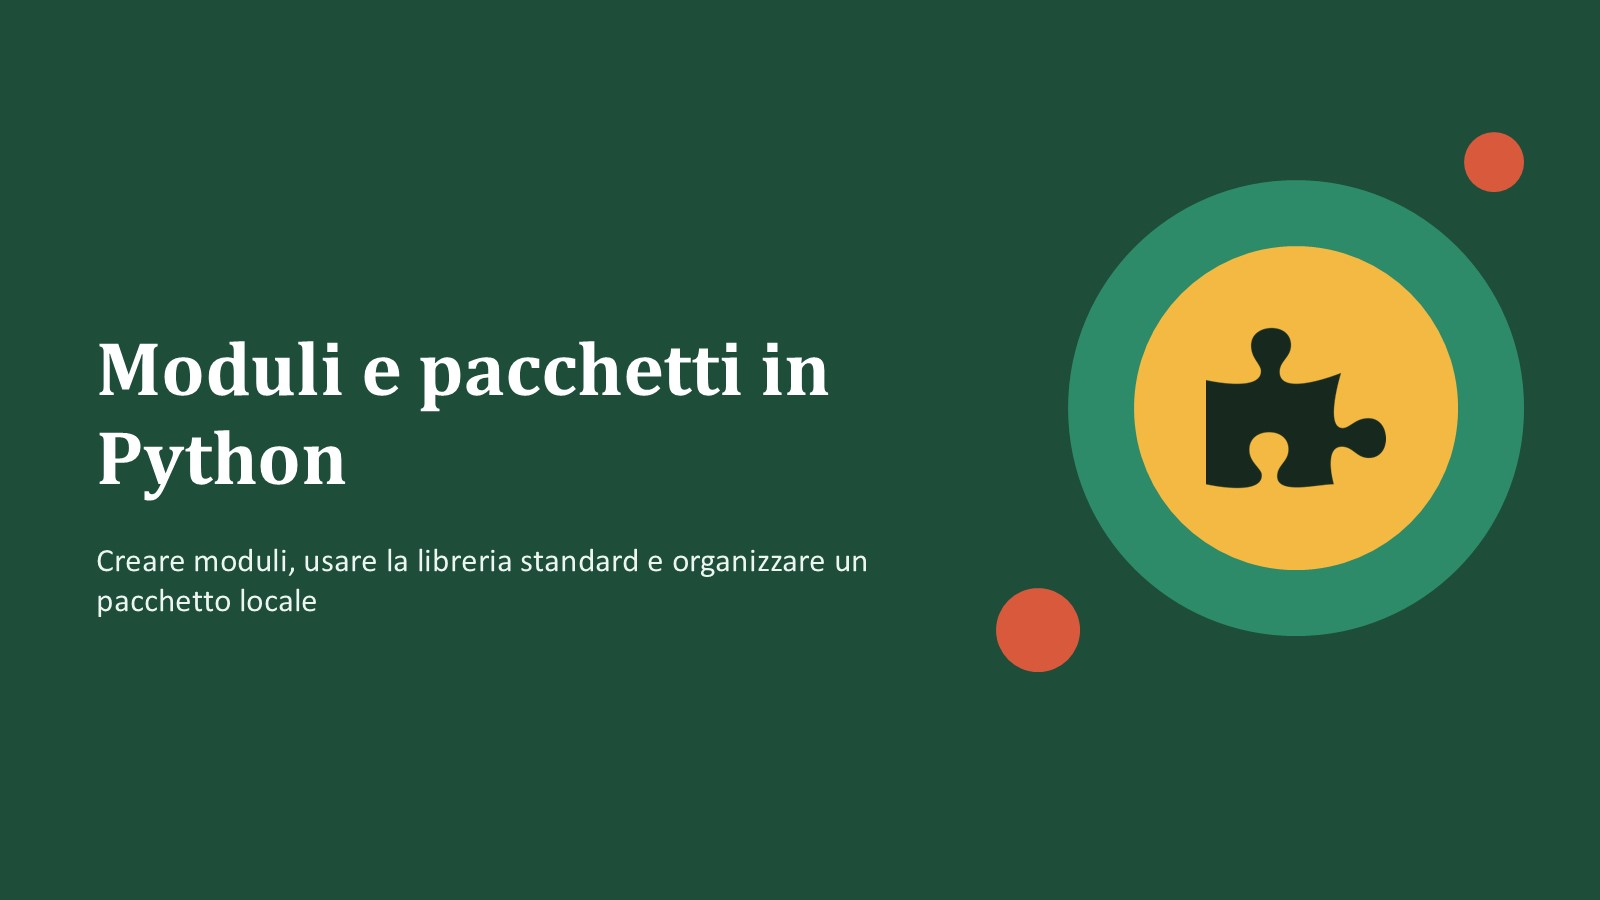

**Moduli e pacchetti · Slide 2 · Che cos'è un modulo**

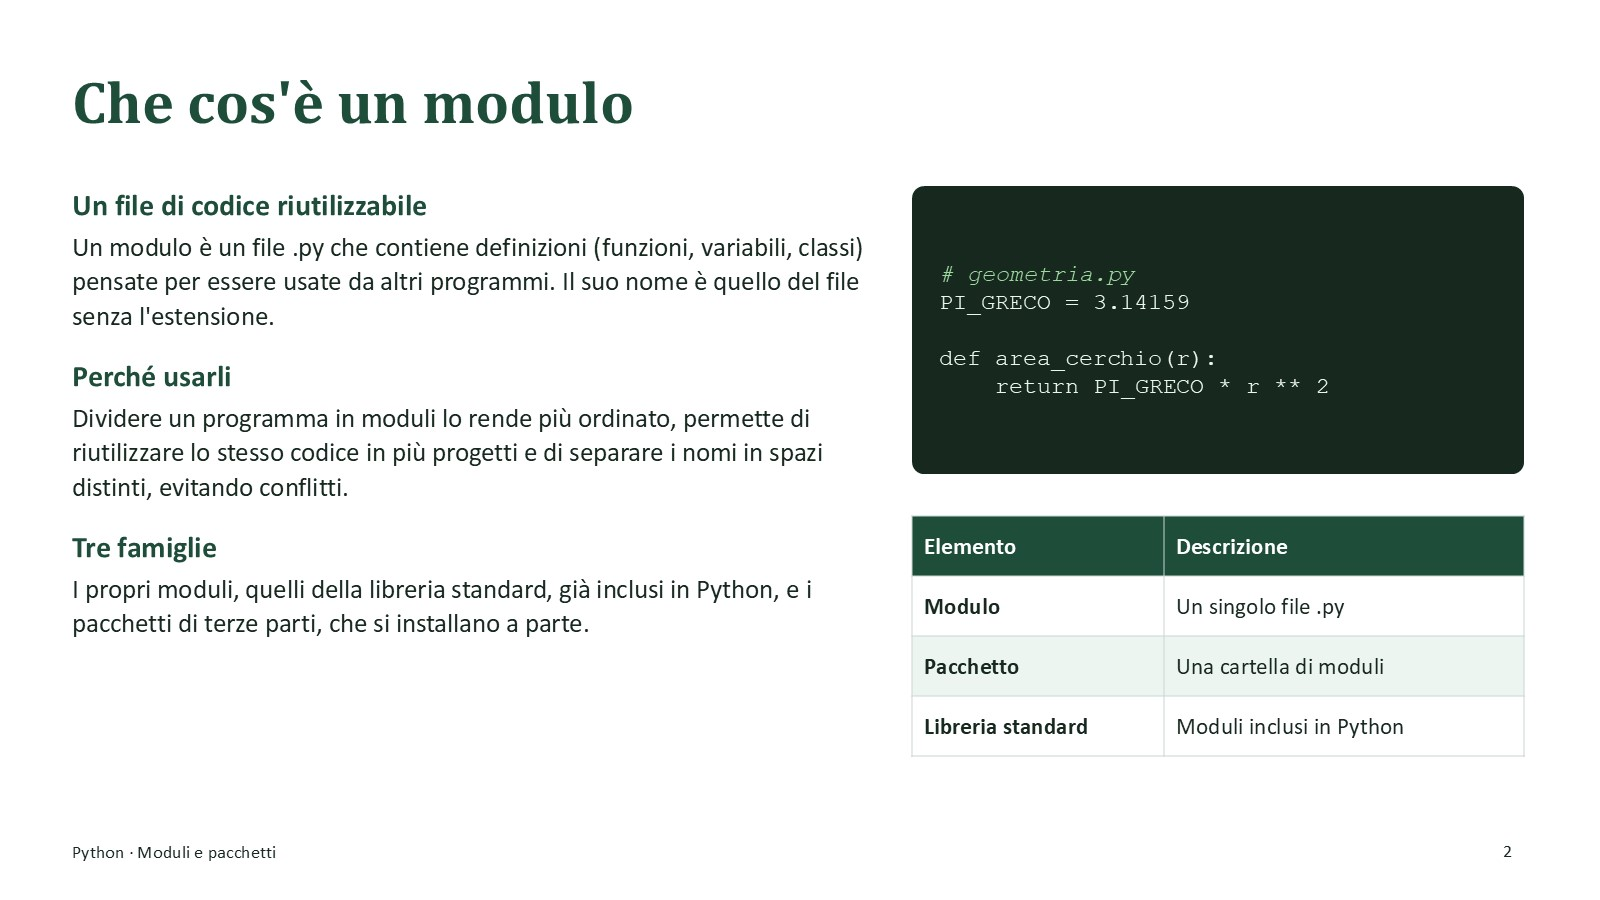

In [ ]:
# in geometria.py
PI_GRECO = 3.14159
 
def area_cerchio(r):
    return PI_GRECO * r ** 2

**Moduli e pacchetti · Slide 3 · Importare un modulo**

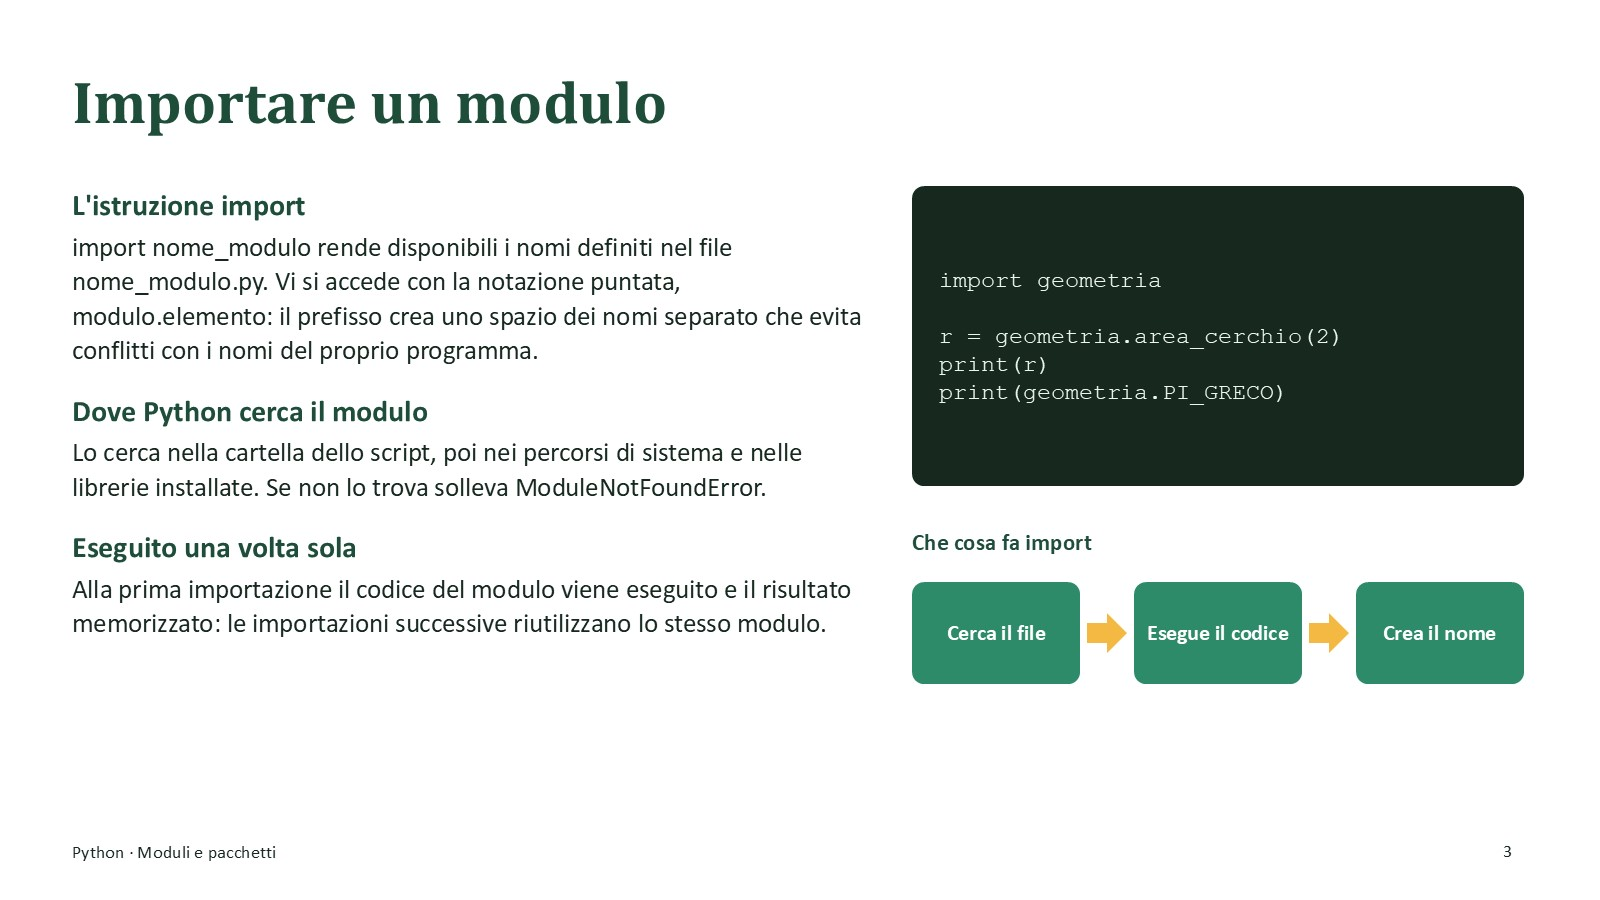

In [ ]:
# in prova_geometria.py
import geometria
 
r = geometria.area_cerchio(2)
print(r)
print(geometria.PI_GRECO)

**Moduli e pacchetti · Slide 4 · Alias e importazioni parziali**

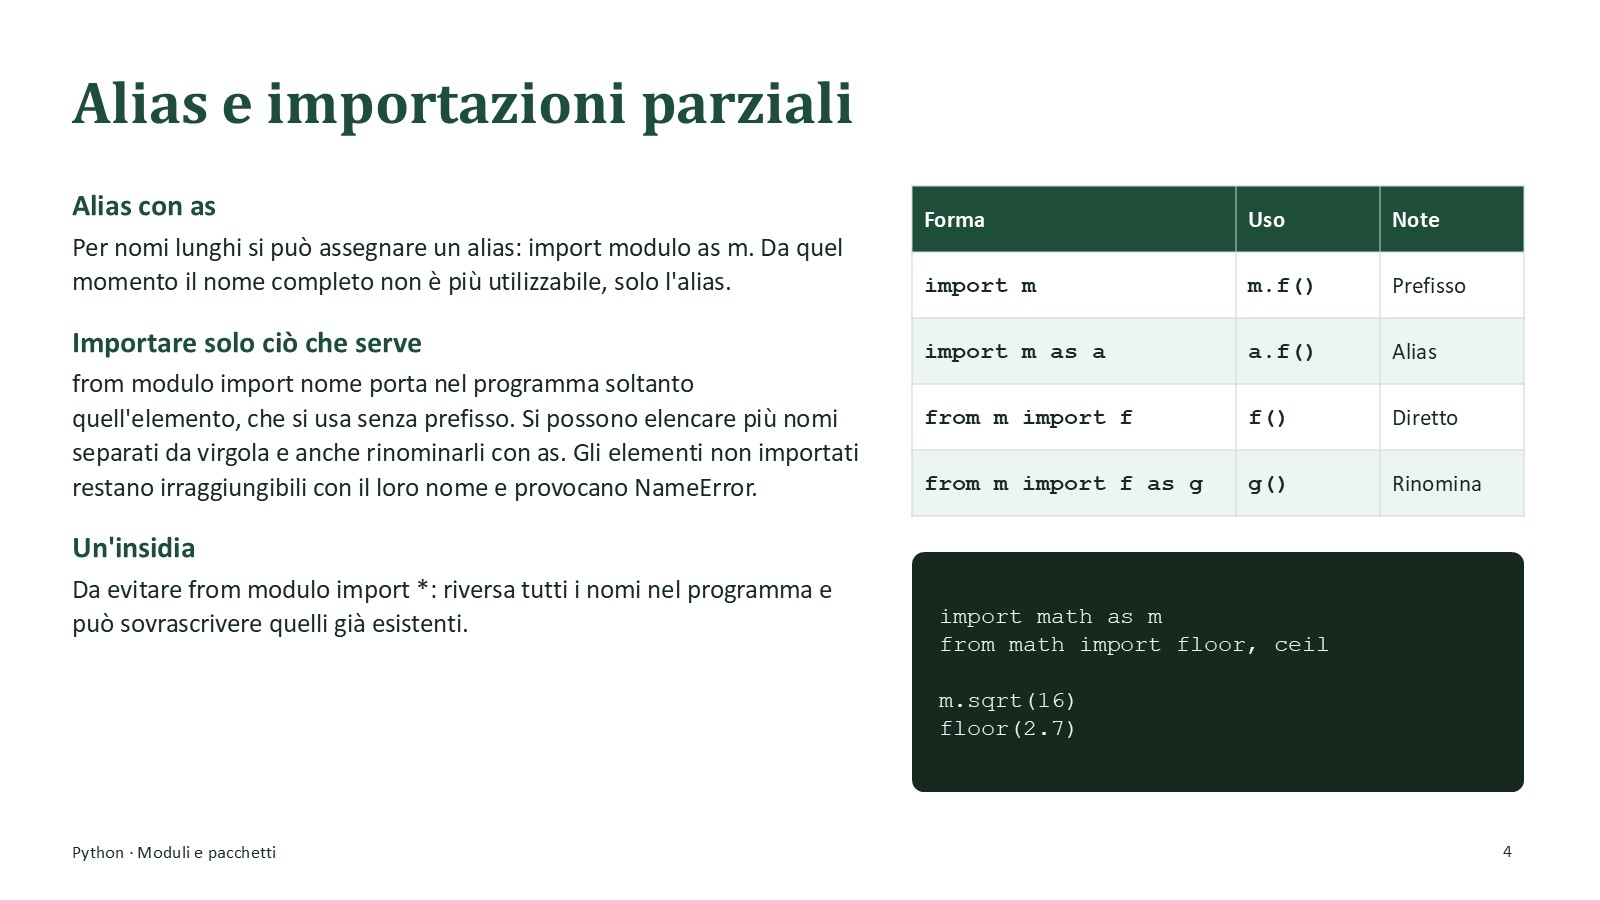

In [ ]:
import math as m
from math import floor, ceil

print(m.sqrt(16))
print(floor(2.7), ceil(2.7))

**Moduli e pacchetti · Slide 5 · Il modulo math**

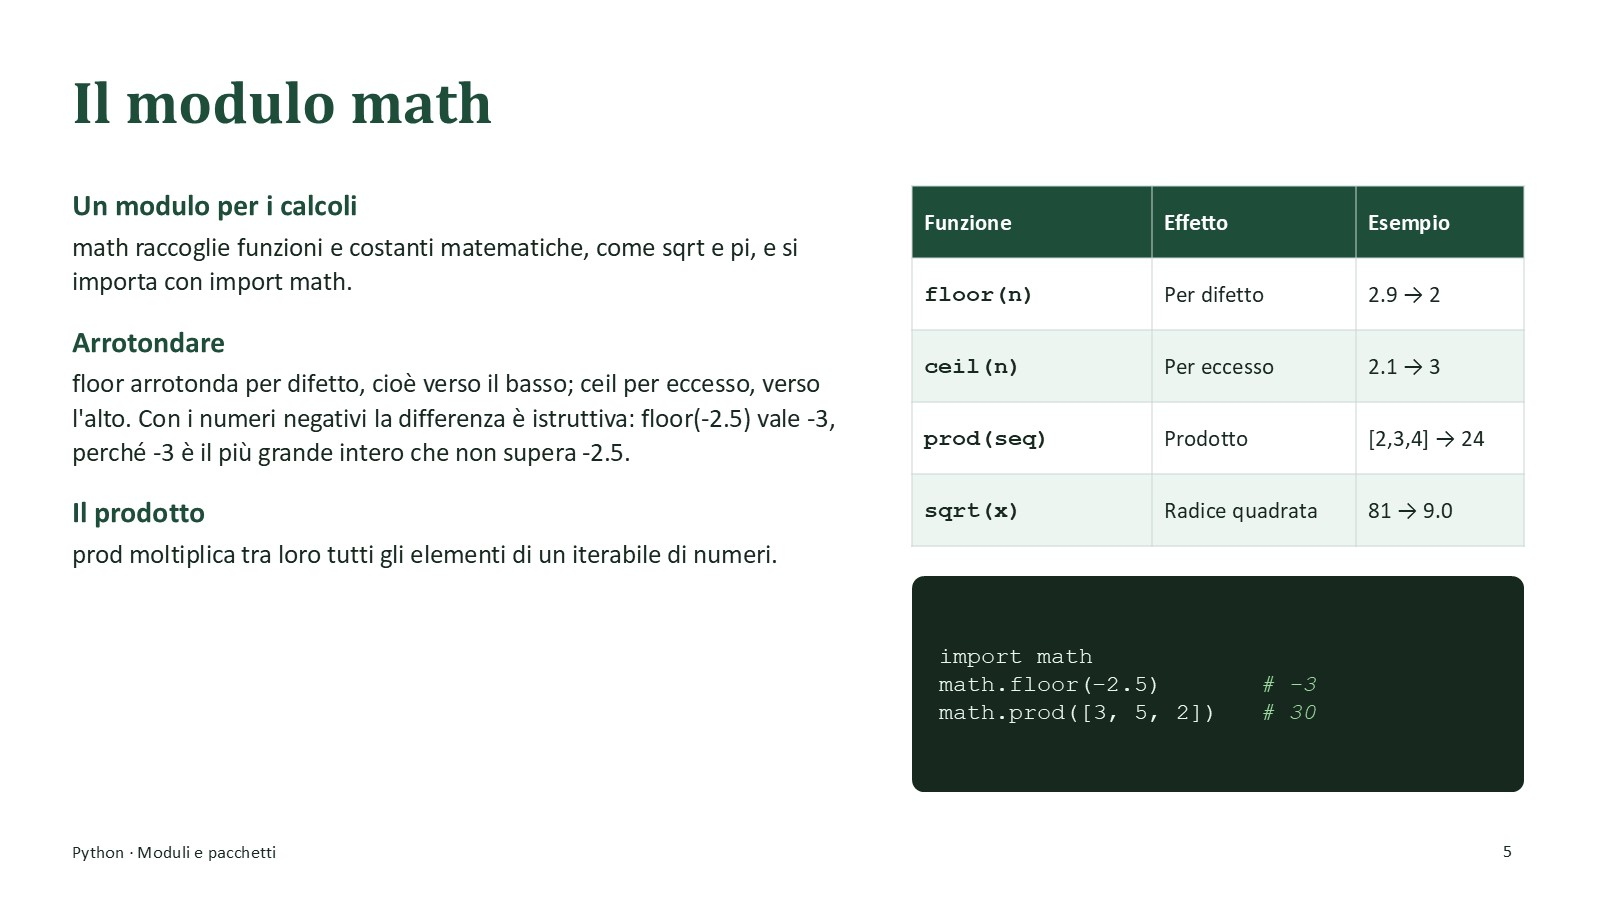

In [ ]:
import math

print(math.floor(-2.5))
print(math.prod([3, 5, 2]))

**Moduli e pacchetti · Slide 6 · Il modulo random**

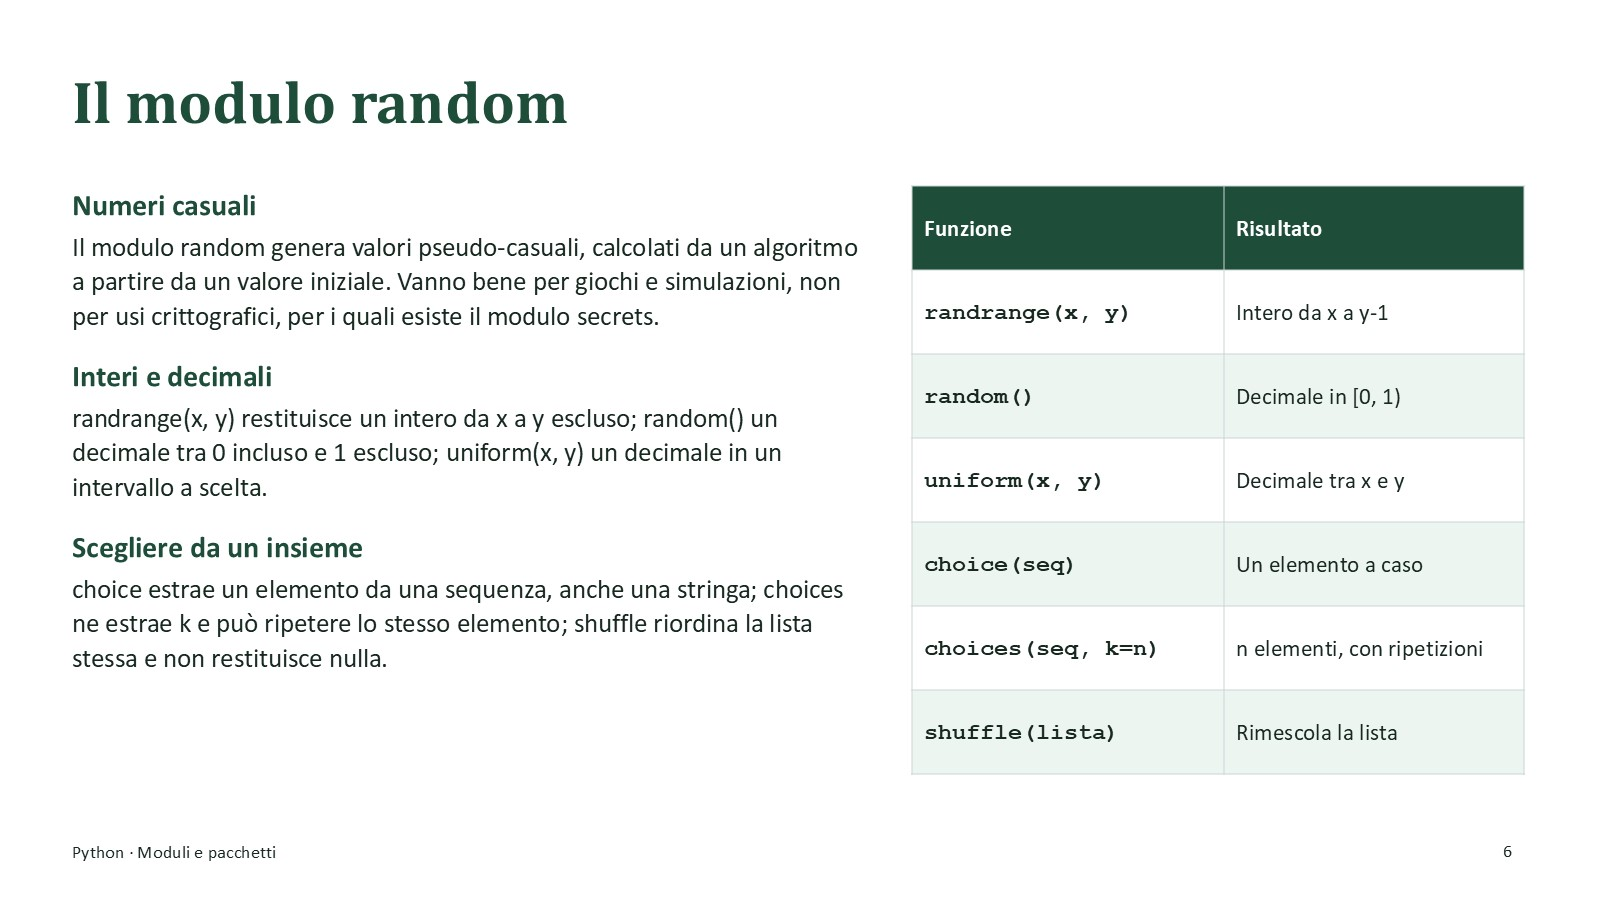

In [ ]:
import random

nomi = ["Ada", "Leo", "Mia"]
print(random.randrange(1, 7))
print(random.random())
print(random.choice(nomi))

**Moduli e pacchetti · Slide 15 · Dal modulo al pacchetto**

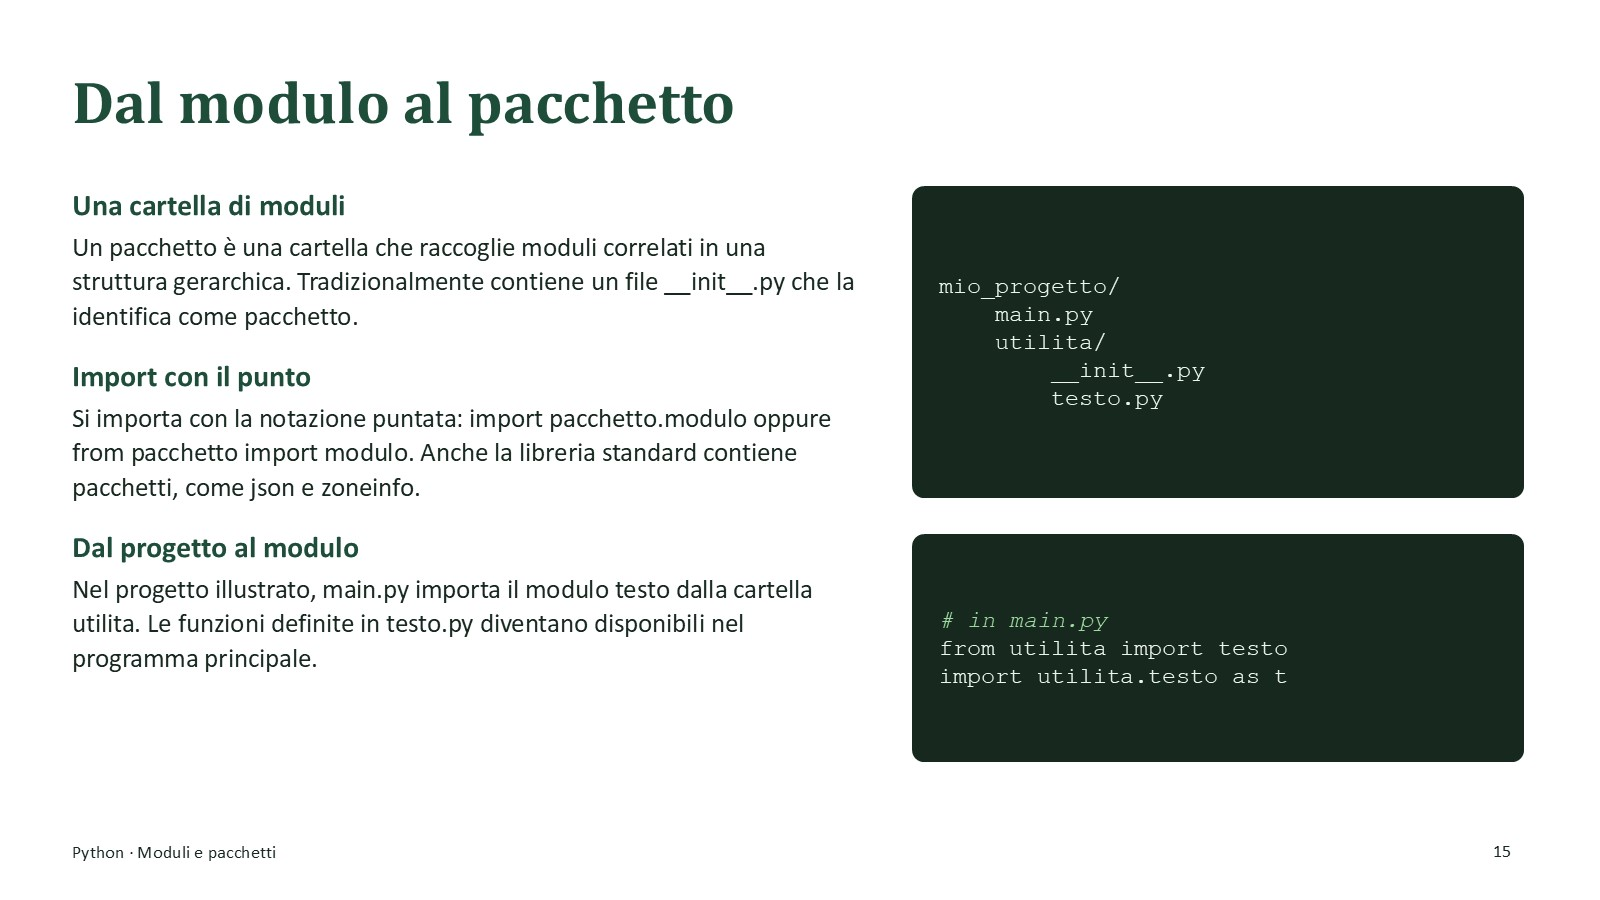

In [ ]:
# in utilita/testo.py
def saluta(nome):
    return "Ciao " + nome

In [ ]:
# in main.py
from utilita import testo
import utilita.testo as t

print(testo.saluta("Ada"))
print(t.saluta("Leo"))

**Programmazione a oggetti · Slide 3 · Il paradigma a oggetti**

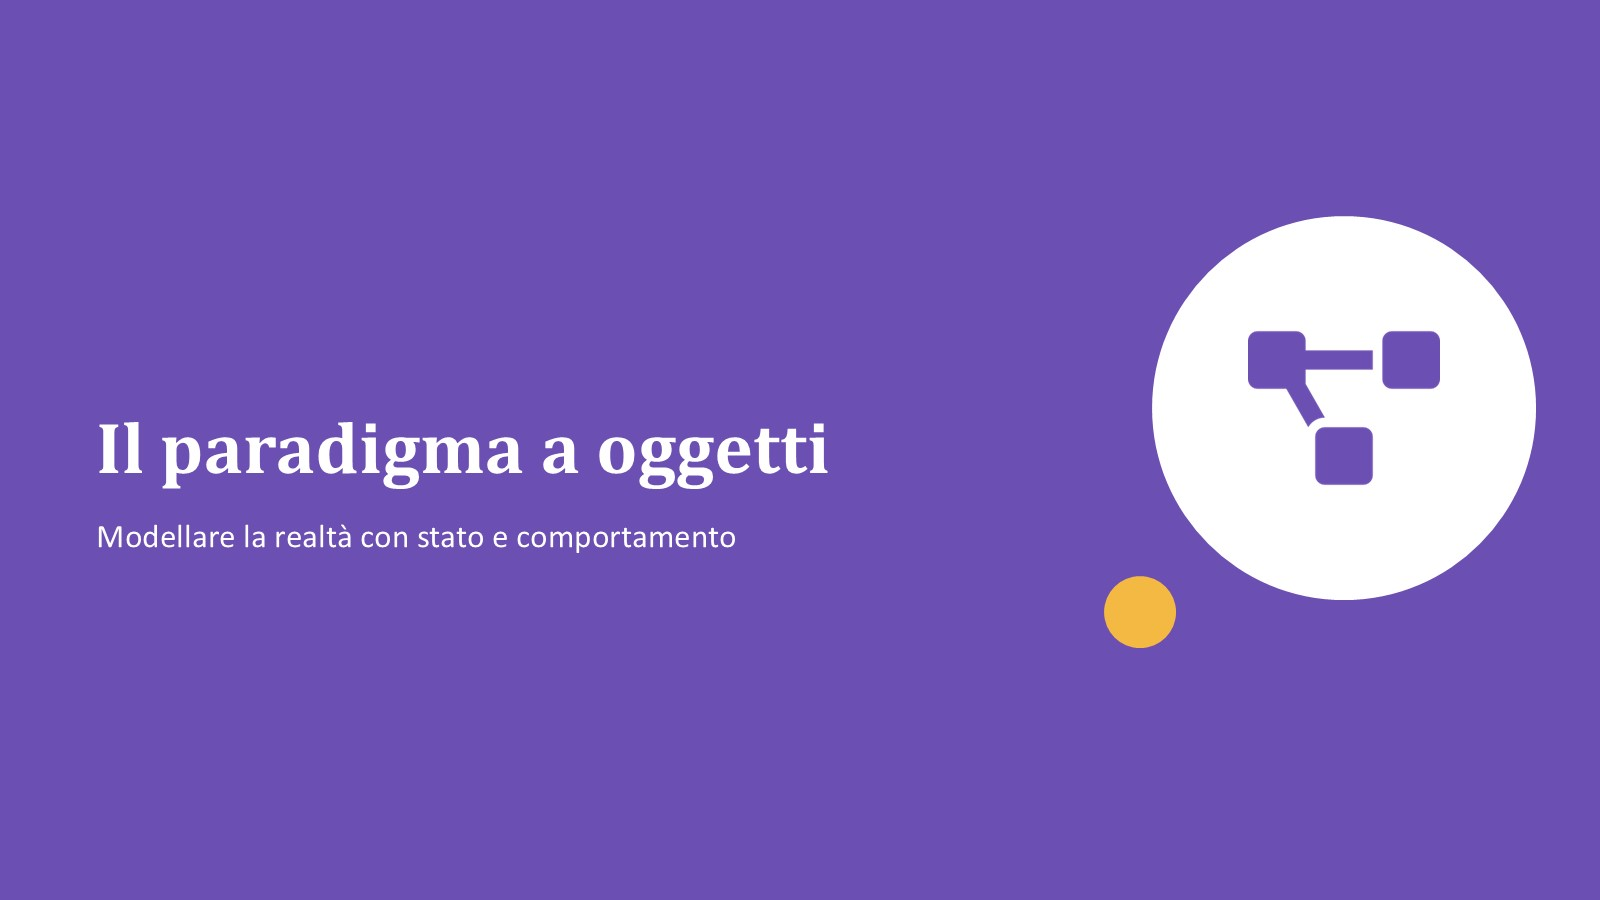

**Programmazione a oggetti · Slide 4 · Pensare per oggetti**

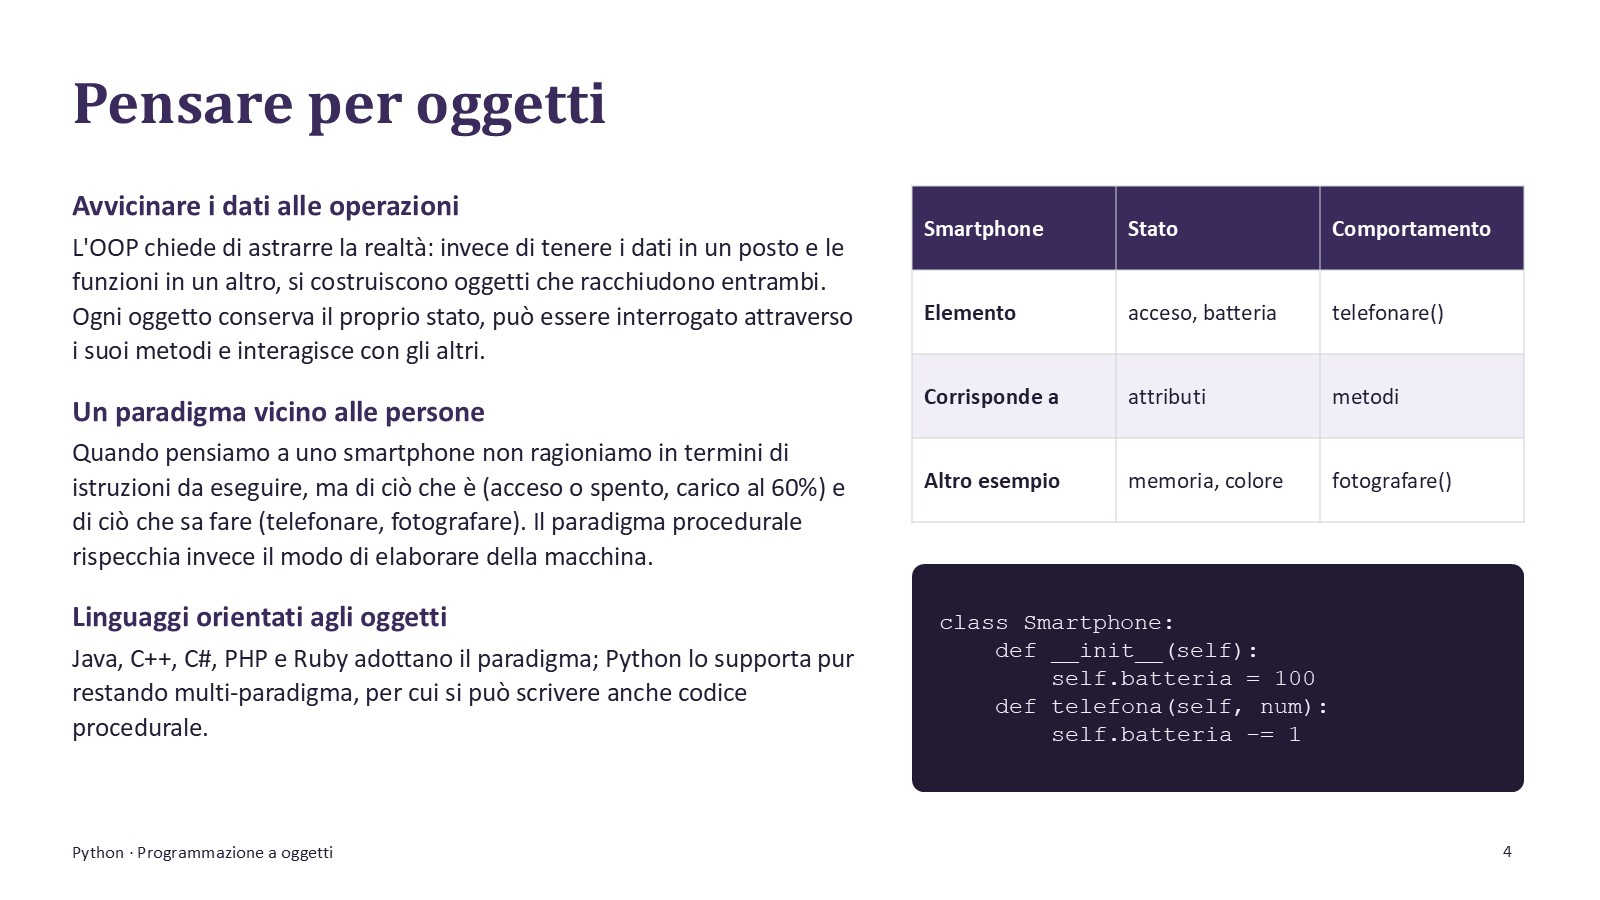

In [ ]:
class Smartphone:
    def __init__(self):
        self.batteria = 100
    def telefona(self, num):
        self.batteria -= 1

telefono = Smartphone()
print(telefono.batteria)
telefono.telefona("123")
print(telefono.batteria)

**Programmazione a oggetti · Slide 5 · Classe, istanza e identità**

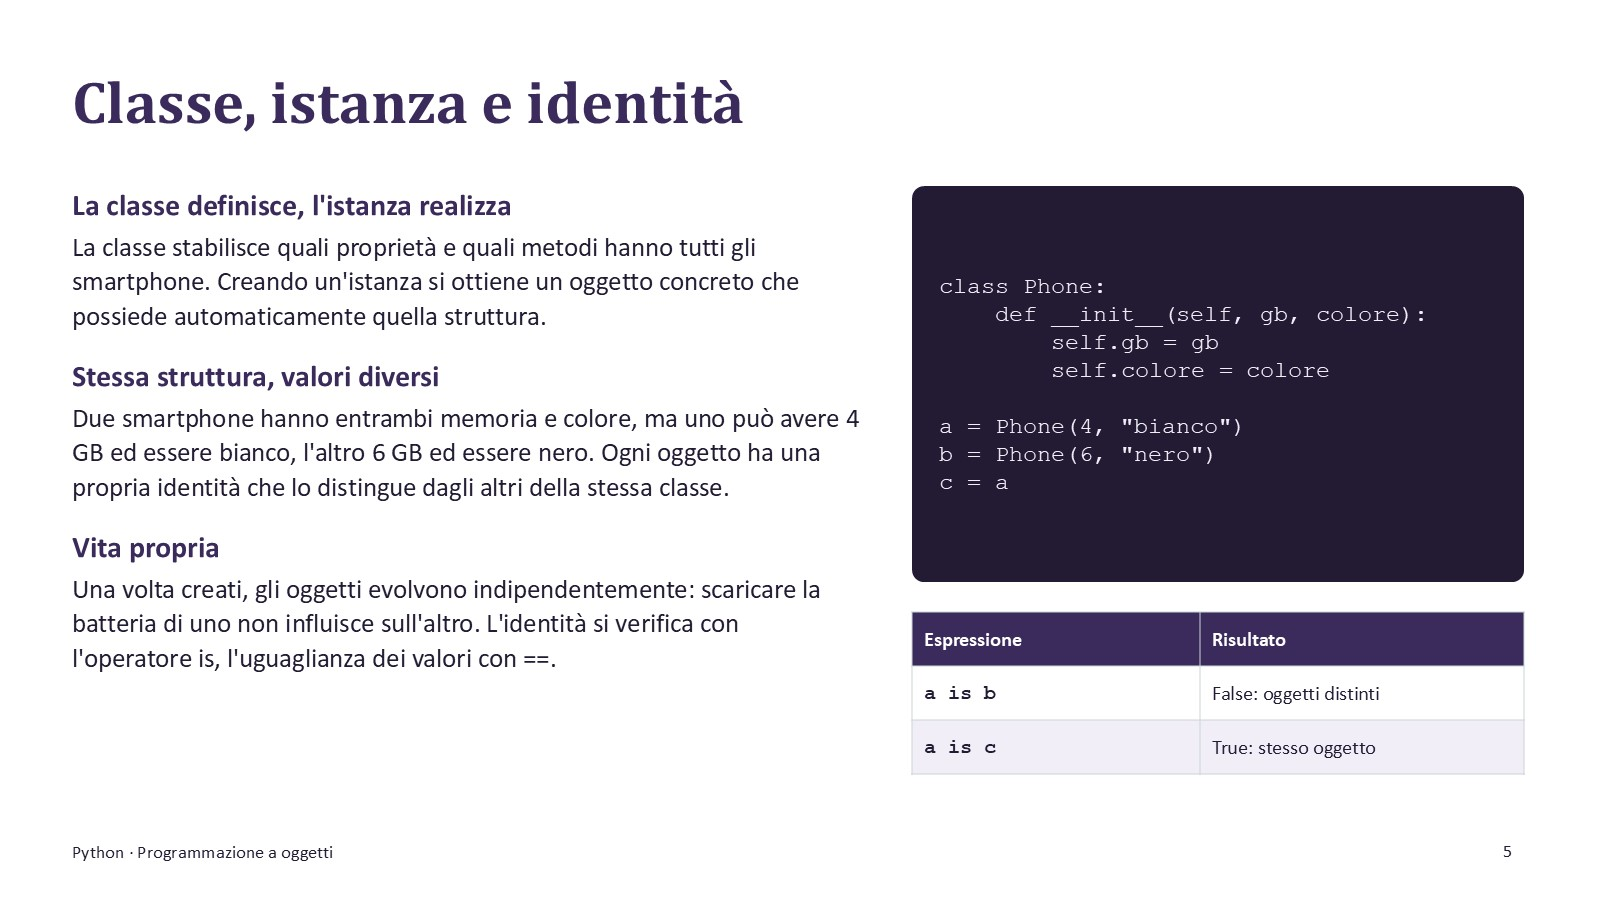

In [ ]:
class Phone:
    def __init__(self, gb, colore):
        self.gb = gb
        self.colore = colore
 
a = Phone(4, "bianco")
b = Phone(6, "nero")
c = a
print(a is b)
print(a is c)

**Programmazione a oggetti · Slide 13 · Classi e oggetti**

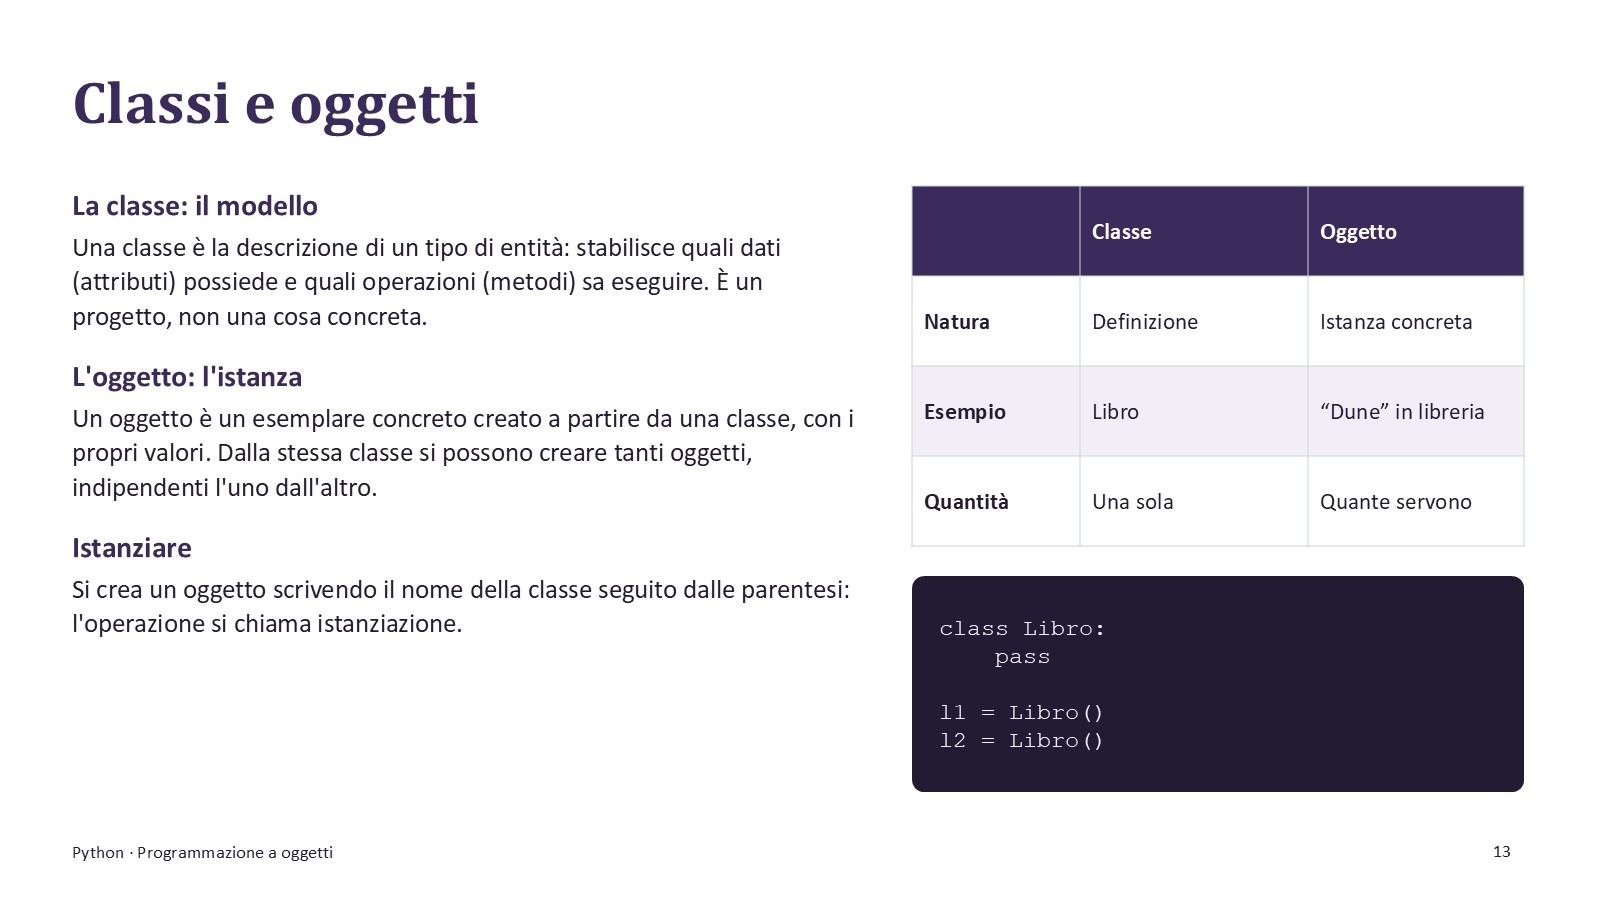

In [1]:
class Libro:
    pass
 
l1 = Libro()
l2 = Libro()
print(l1 is l2)

False


**Programmazione a oggetti · Slide 14 · Il costruttore __init__ e il parametro self**

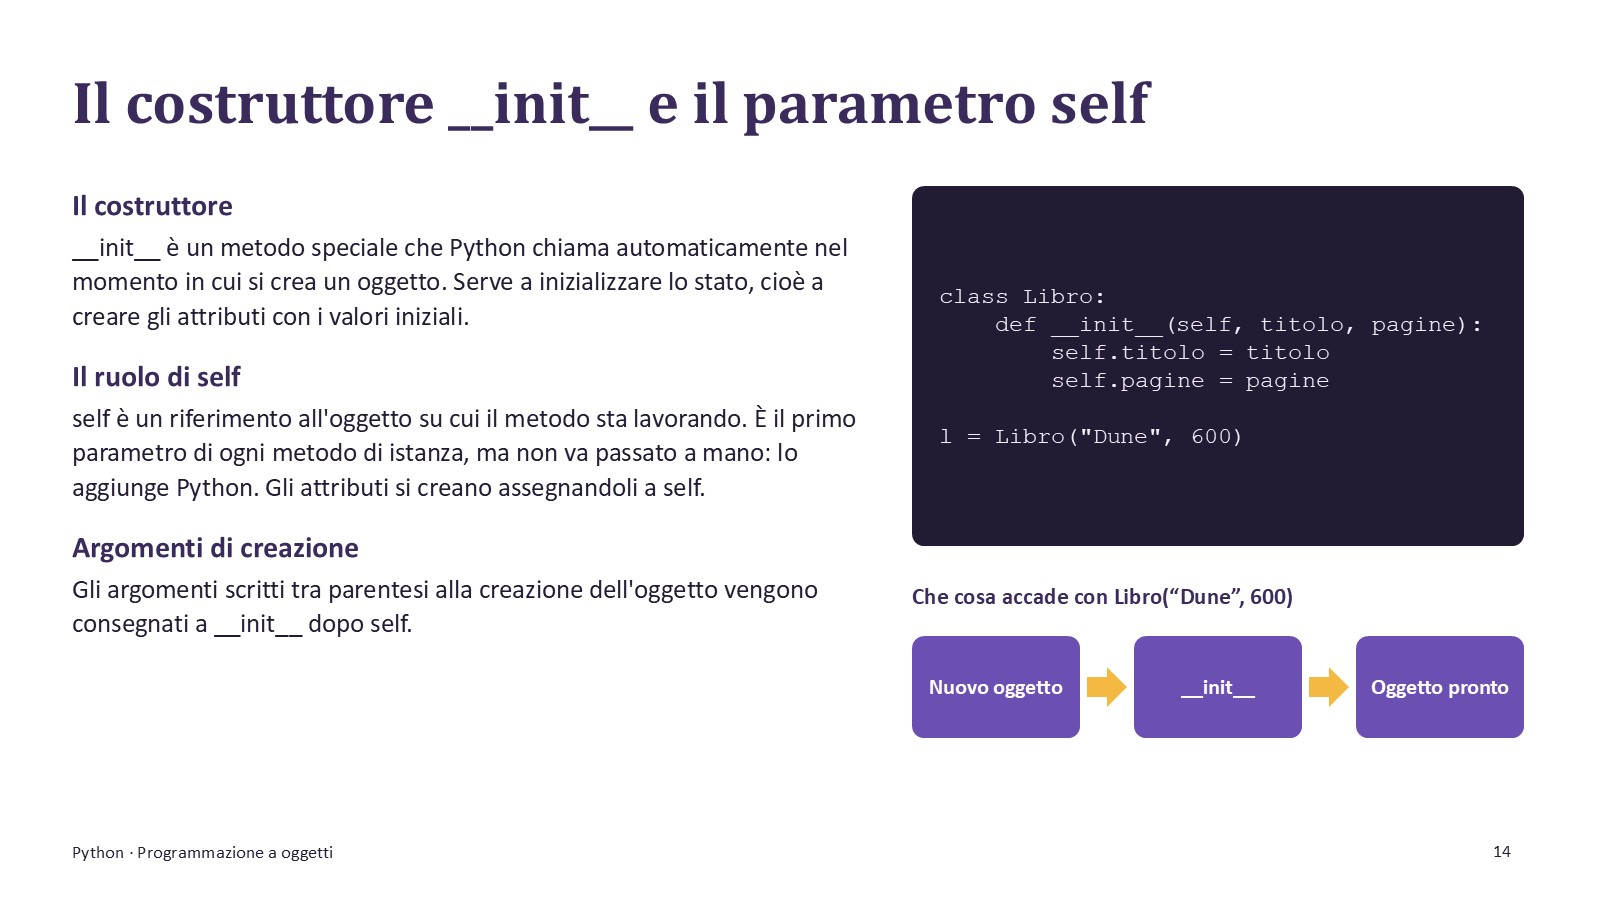

In [ ]:
class Libro:
    def __init__(self, titolo, pagine):
        self.titolo = titolo
        self.pagine = pagine
 
l = Libro("Dune", 600)
print(l.titolo, l.pagine)

**Programmazione a oggetti · Slide 15 · Attributi e metodi**

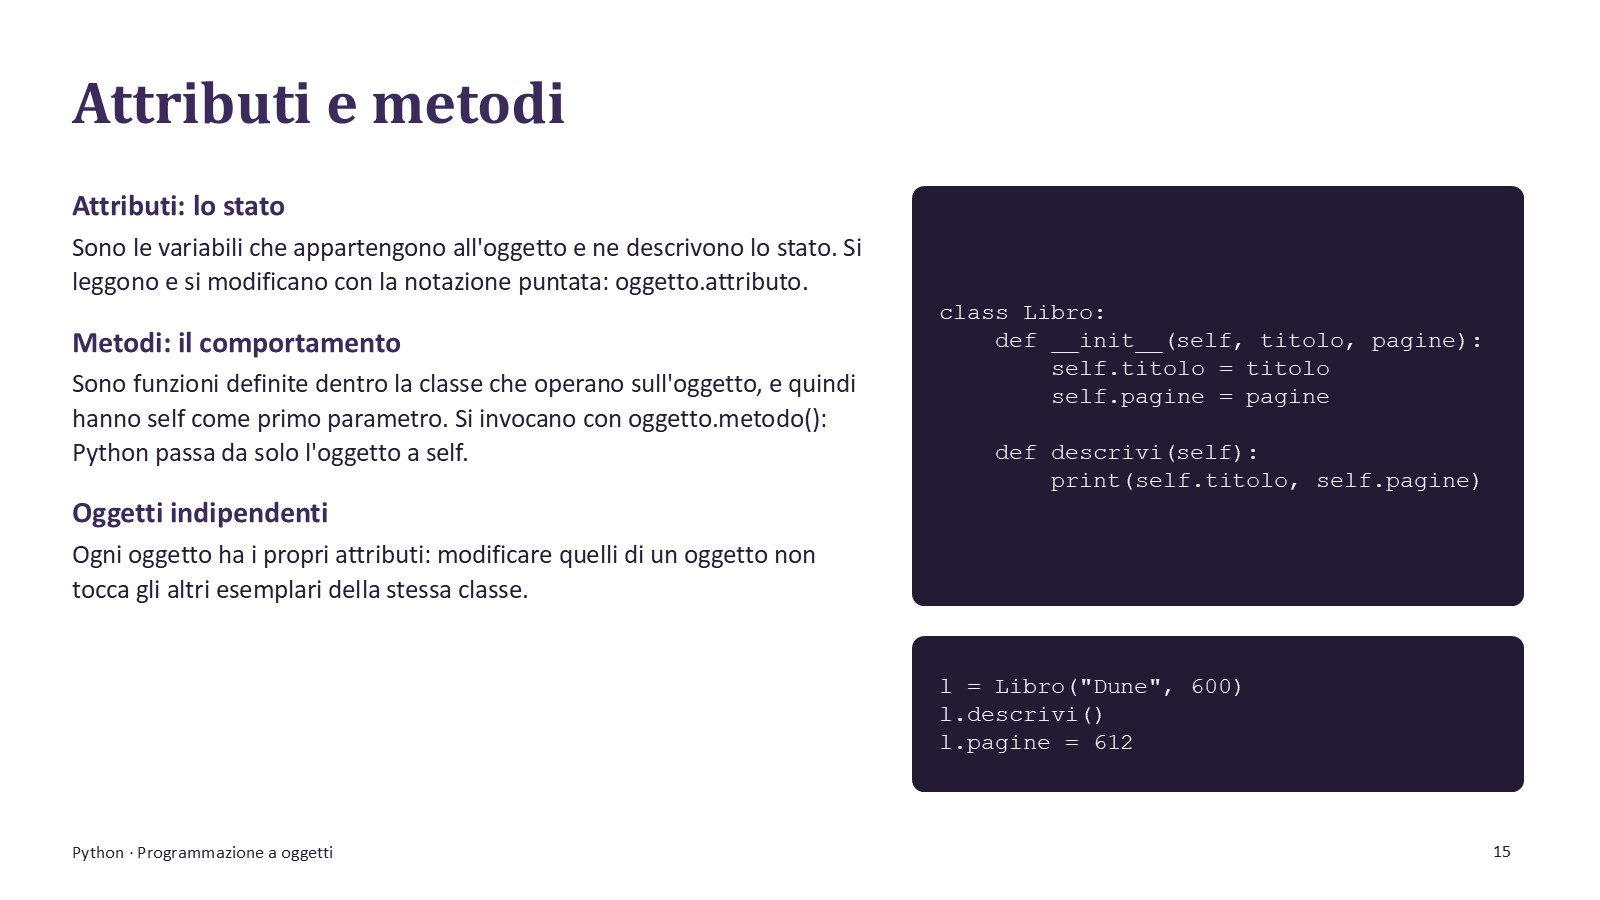

In [ ]:
class Libro:
    def __init__(self, titolo, pagine):
        self.titolo = titolo
        self.pagine = pagine
 
    def descrivi(self):
        print(self.titolo, self.pagine)

l = Libro("Dune", 600)
l.descrivi()
l.pagine = 612
l.descrivi()

**Programmazione a oggetti · Slide 17 · L'ereditarietà**

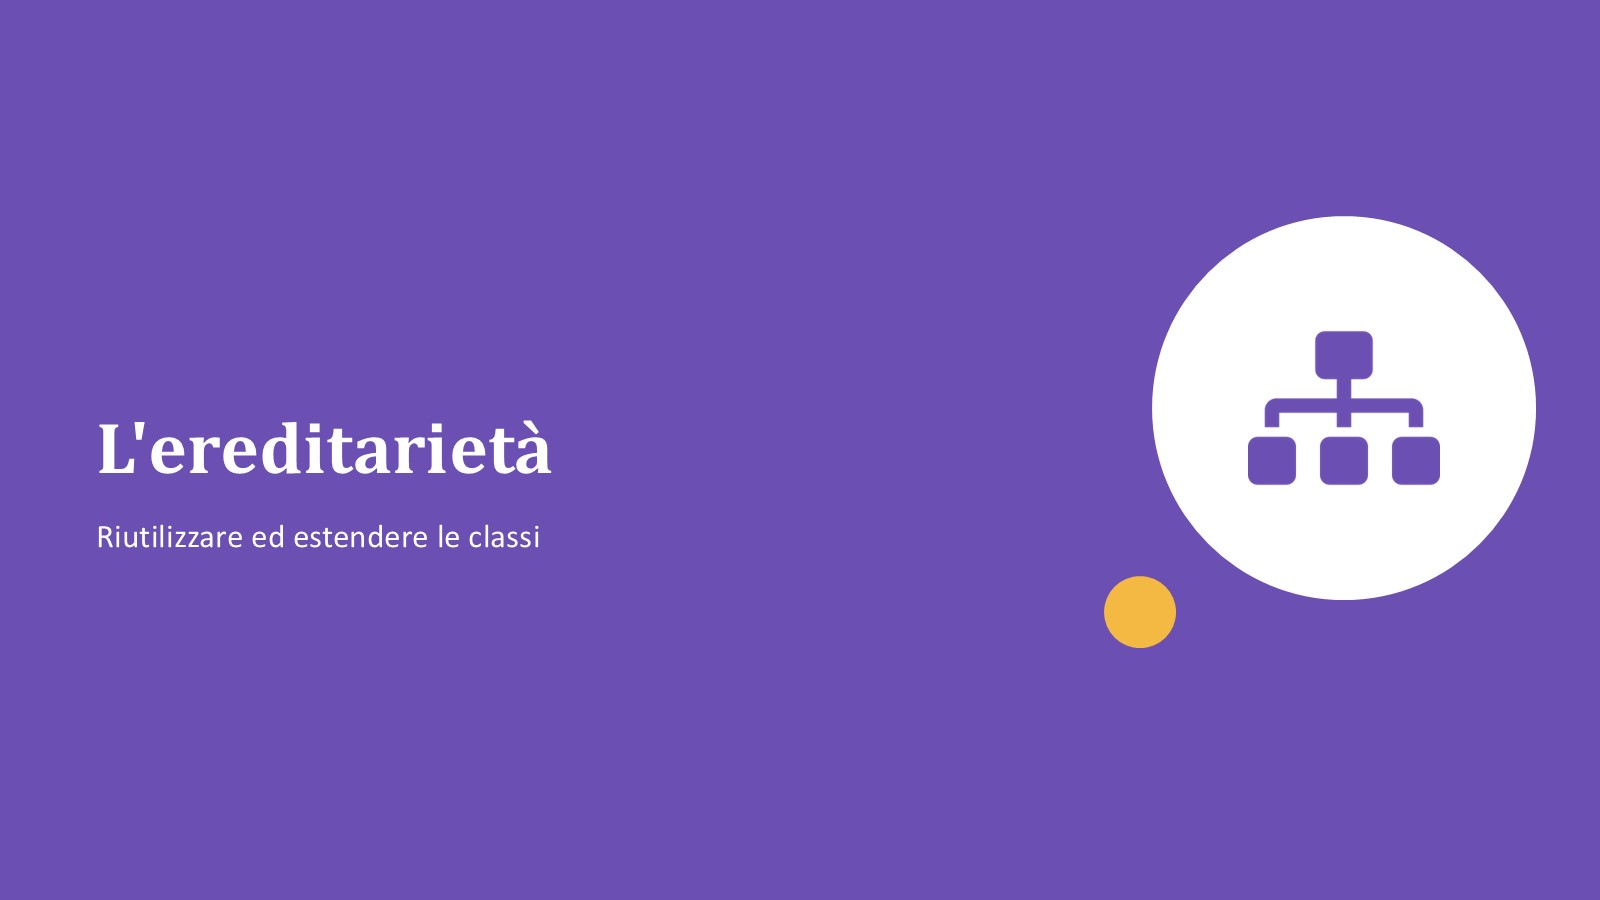

**Programmazione a oggetti · Slide 18 · Che cos'è l'ereditarietà**

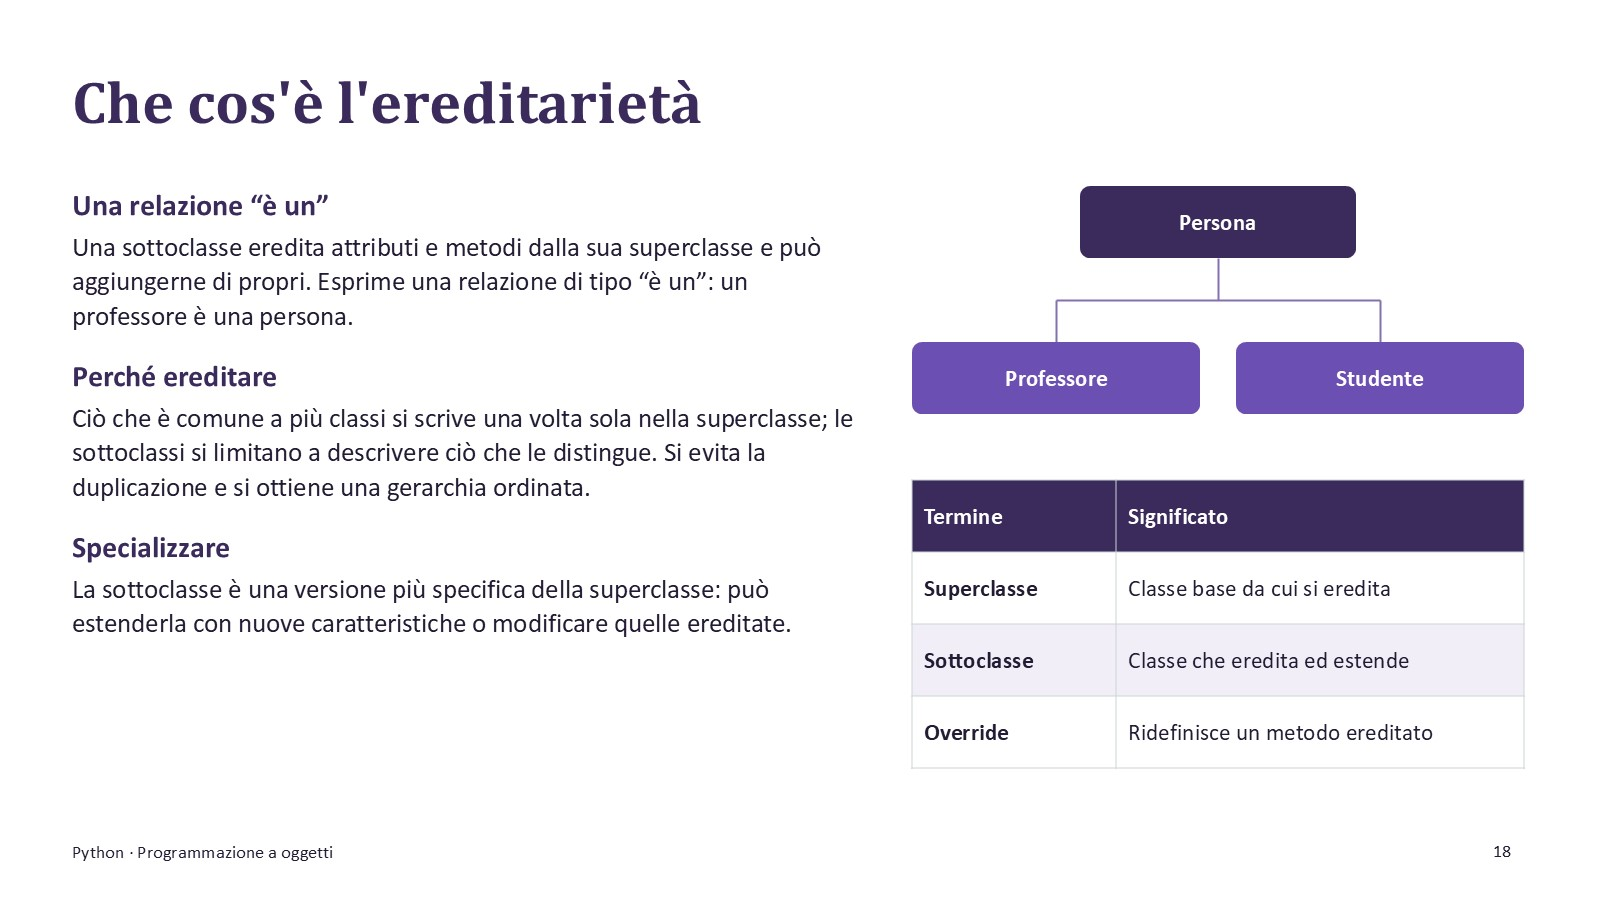

In [ ]:
class Persona:
    def __init__(self, nome):
        self.nome = nome

    def presentati(self):
        print("Sono", self.nome)


class Studente(Persona):
    pass


studentessa = Studente("Ada")
studentessa.presentati()

**Programmazione a oggetti · Slide 19 · Definire una sottoclasse e usare super()**

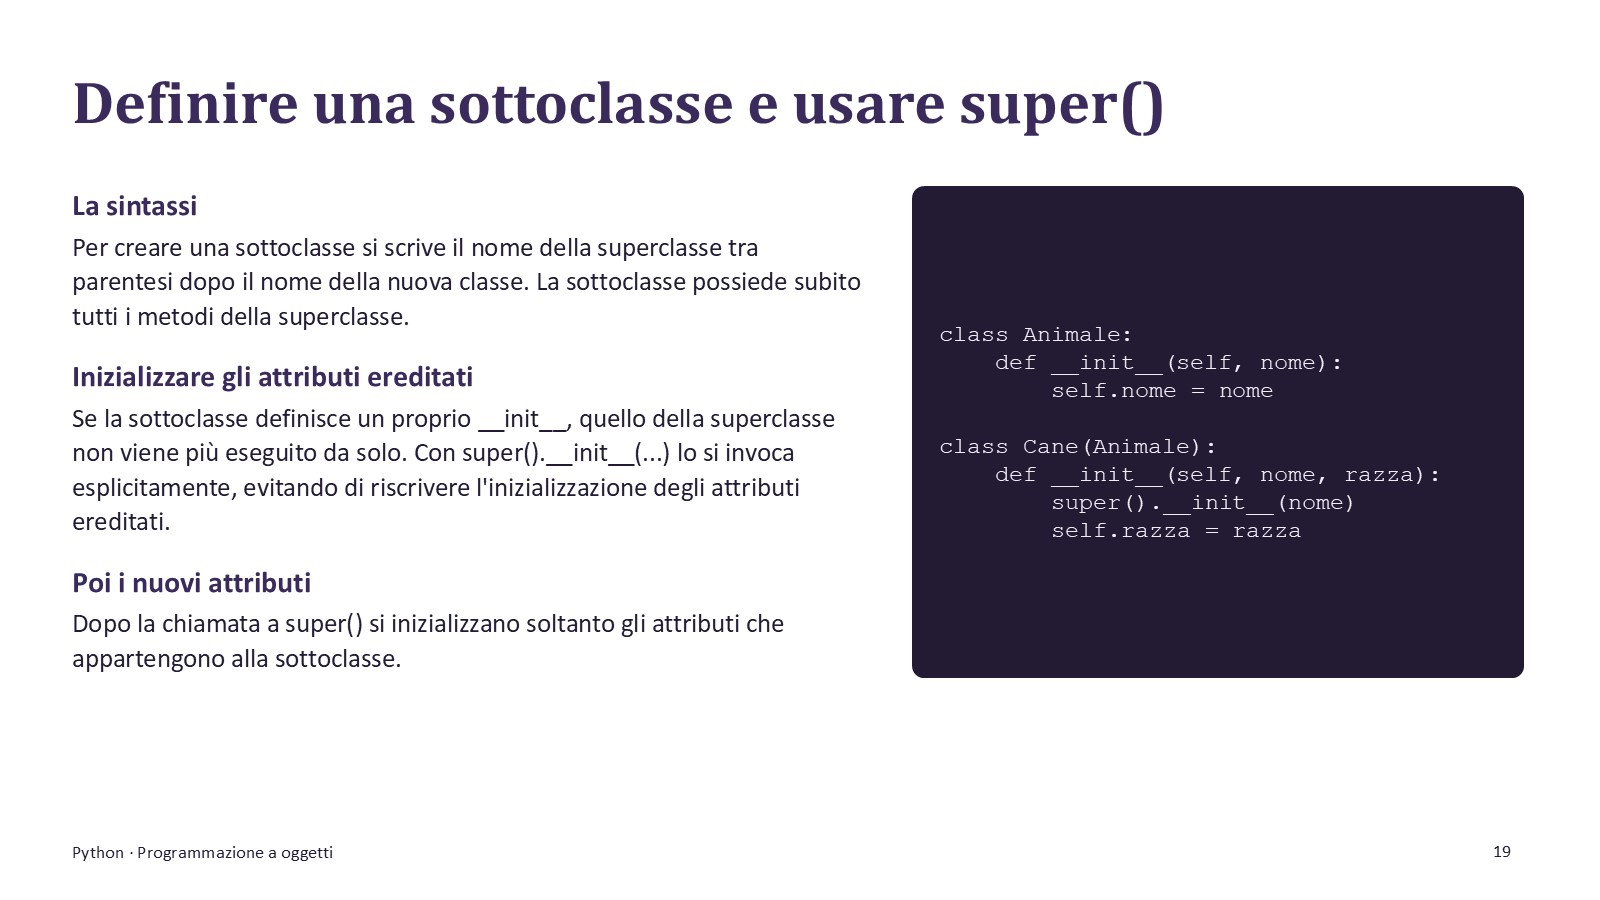

In [ ]:
class Animale:
    def __init__(self, nome):
        self.nome = nome
 
class Cane(Animale):
    def __init__(self, nome, razza):
        super().__init__(nome)
        self.razza = razza

fido = Cane("Fido", "Beagle")
print(fido.nome)
print(fido.razza)

**Programmazione a oggetti · Slide 20 · Override e polimorfismo**

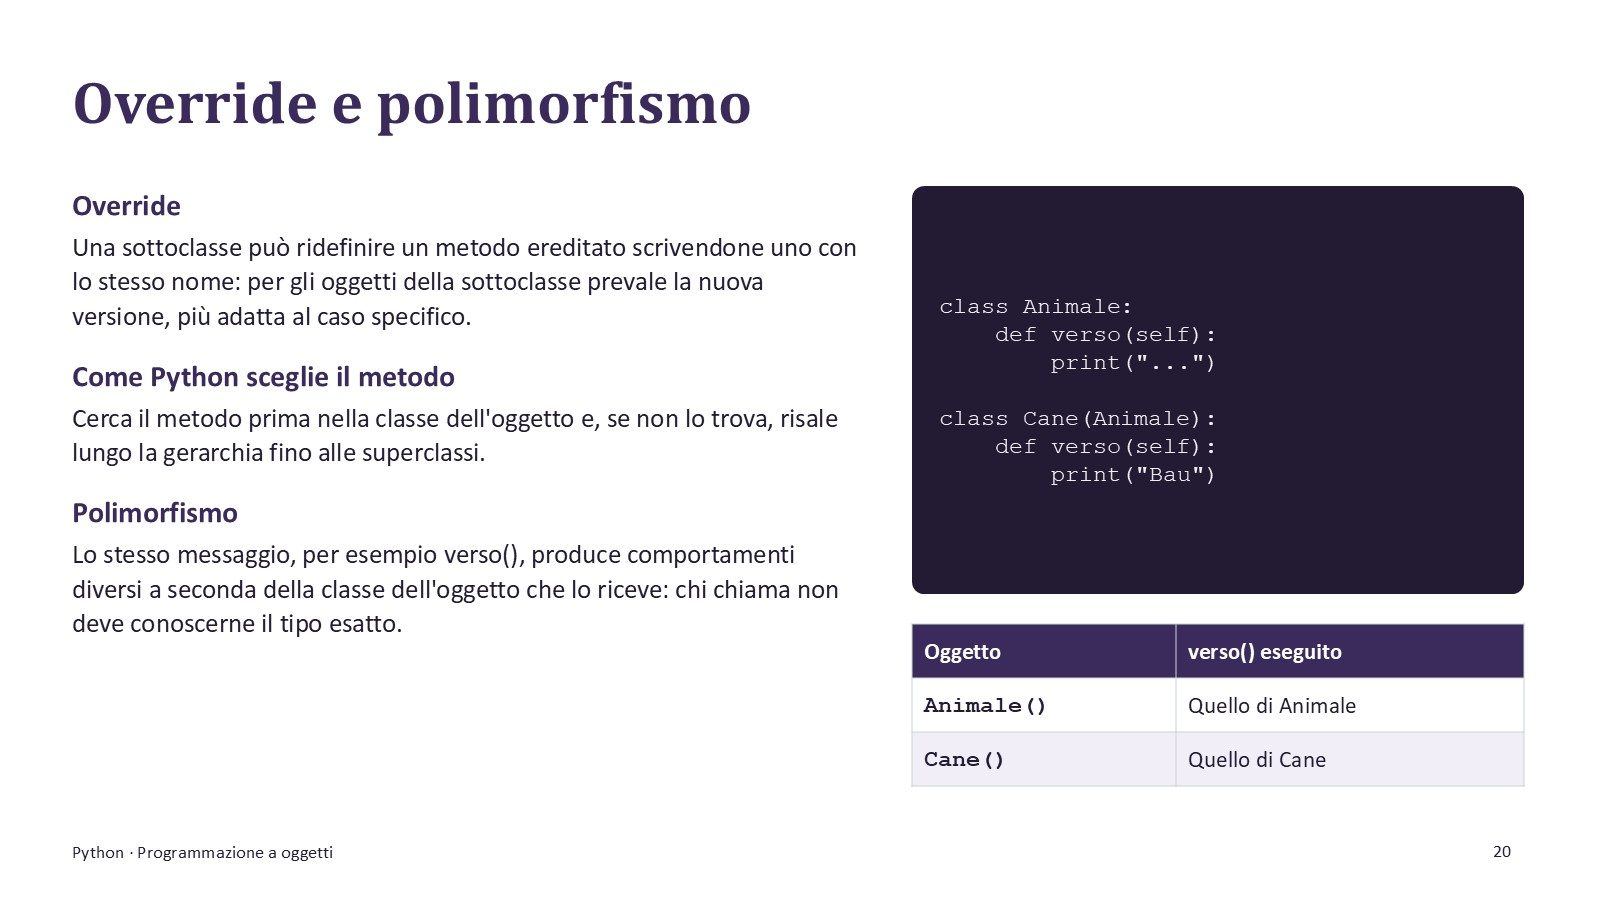

In [ ]:
class Animale:
    def verso(self):
        print("...")
 
class Cane(Animale):
    def verso(self):
        print("Bau")

for animale in [Animale(), Cane()]:
    animale.verso()

**File e pathlib · Slide 1 · Gestione dei file in Python**

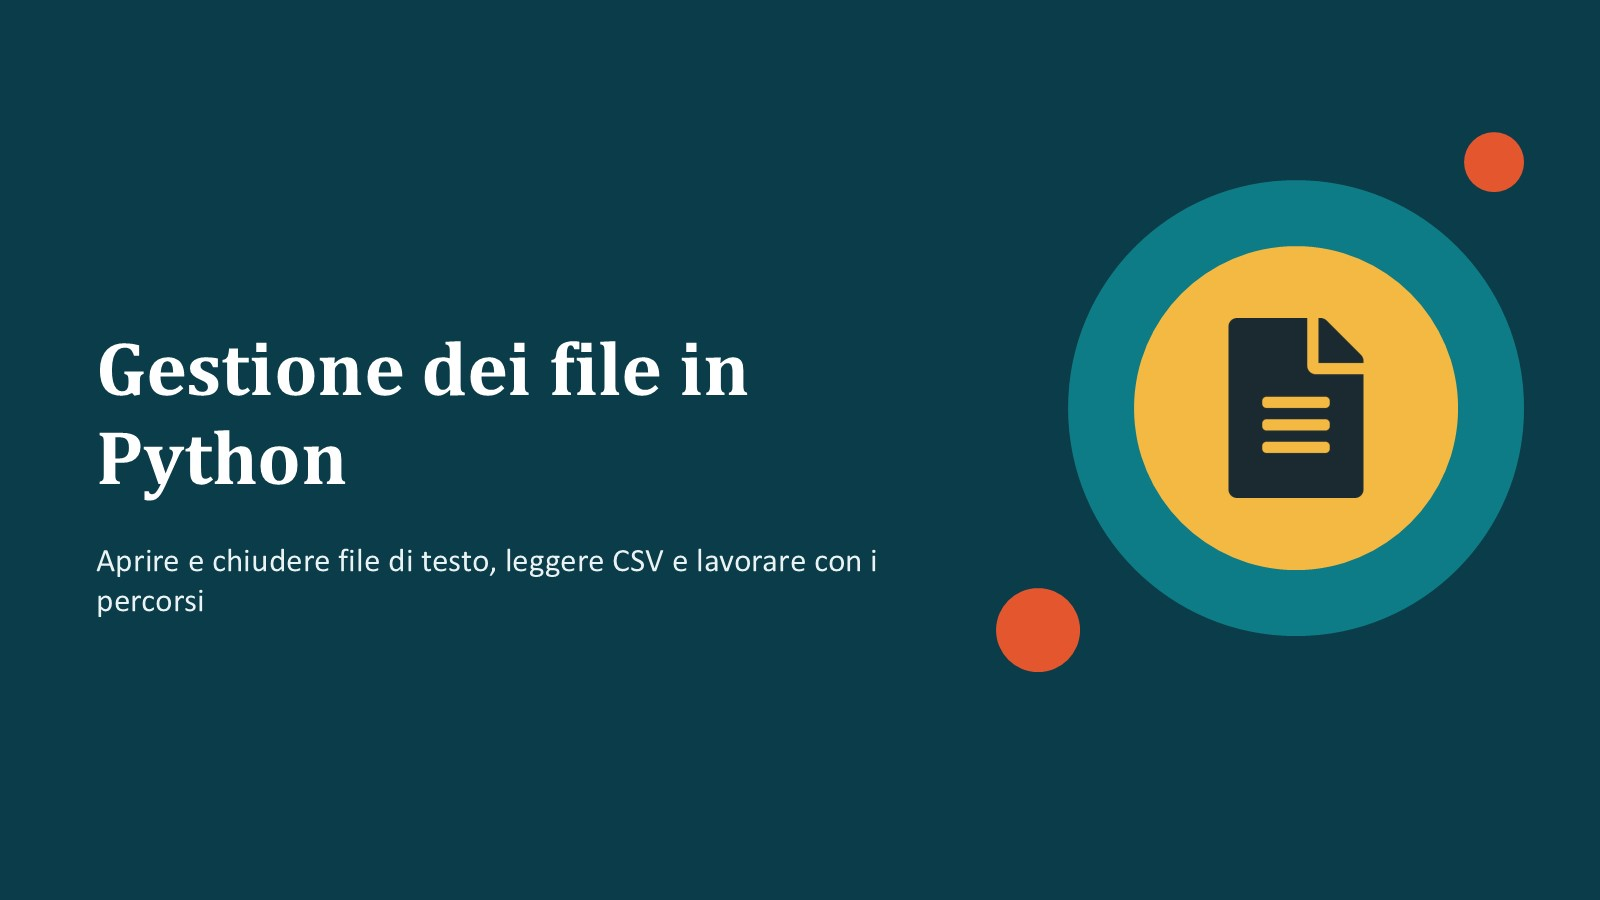

**File e pathlib · Slide 2 · Perché servono i file**

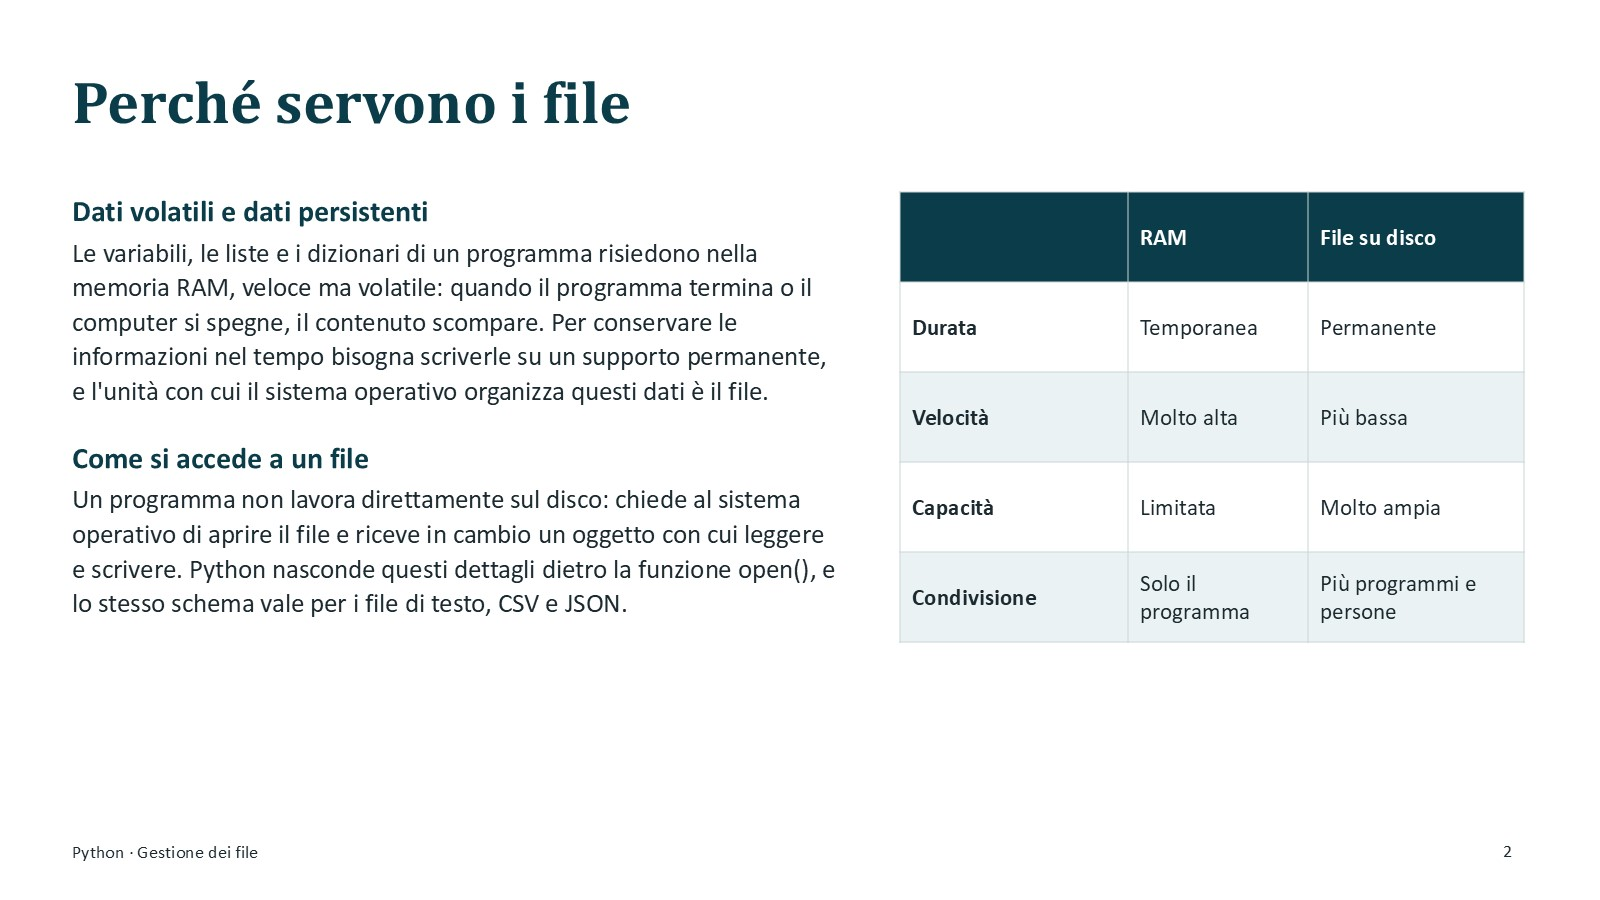

**Salva come `note.txt` nella cartella di lavoro del notebook.**

```text
CIAO MONDO
A DOMANI
```

**File e pathlib · Slide 3 · Il ciclo di vita di un file**

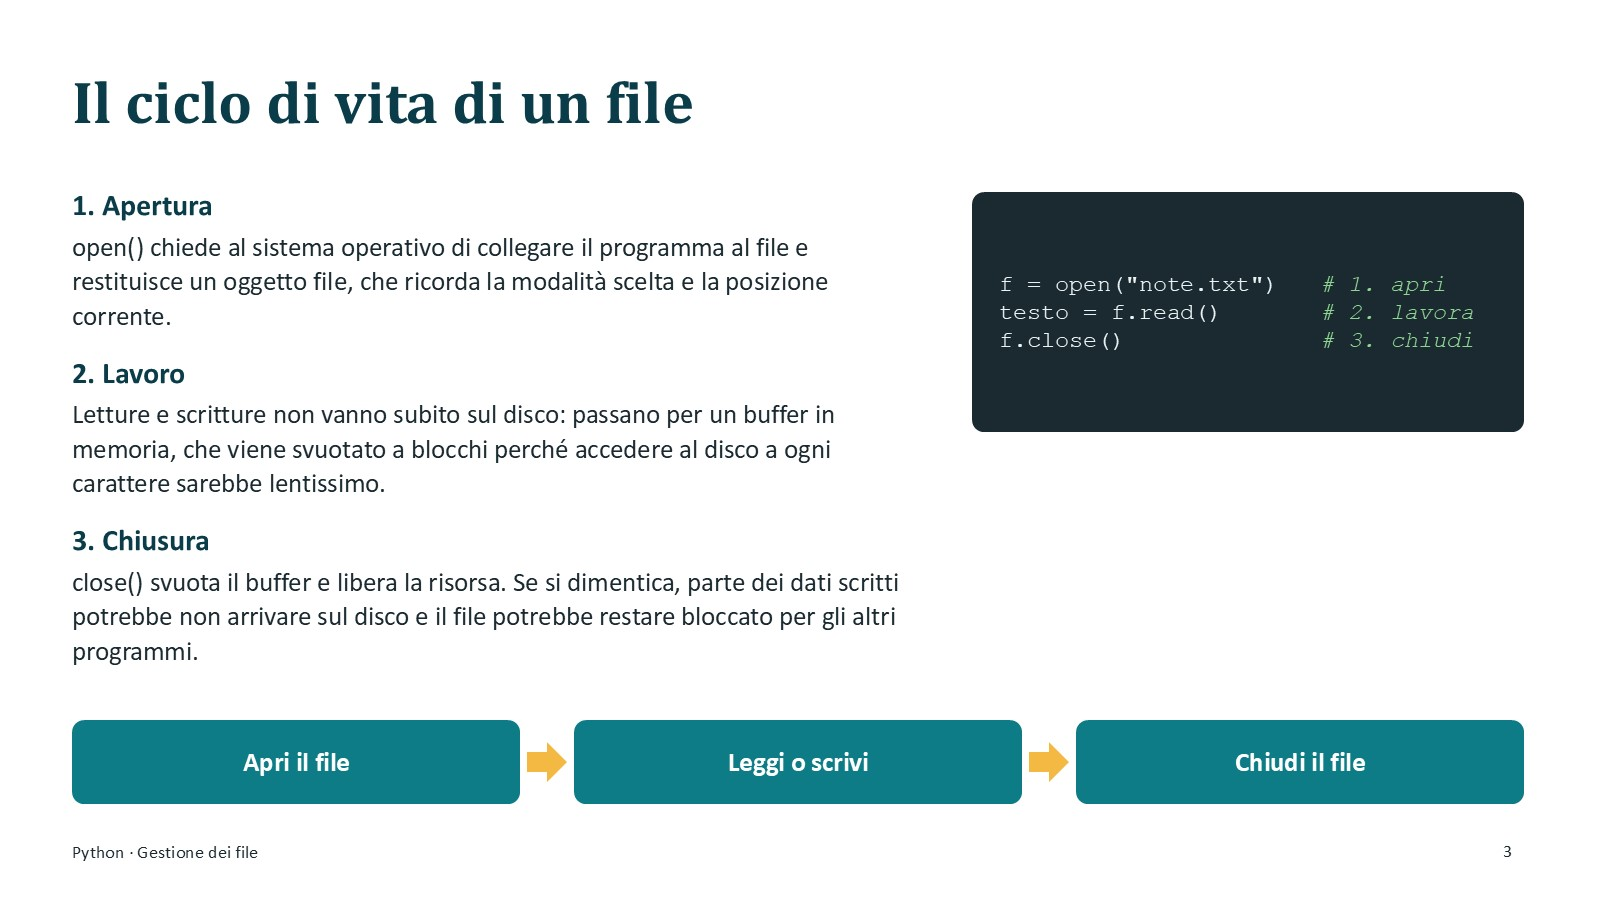

In [ ]:
f = open("note.txt")
testo = f.read()
f.close()
print(testo)
print(f.closed)

**File e pathlib · Slide 4 · open(): le modalità di accesso**

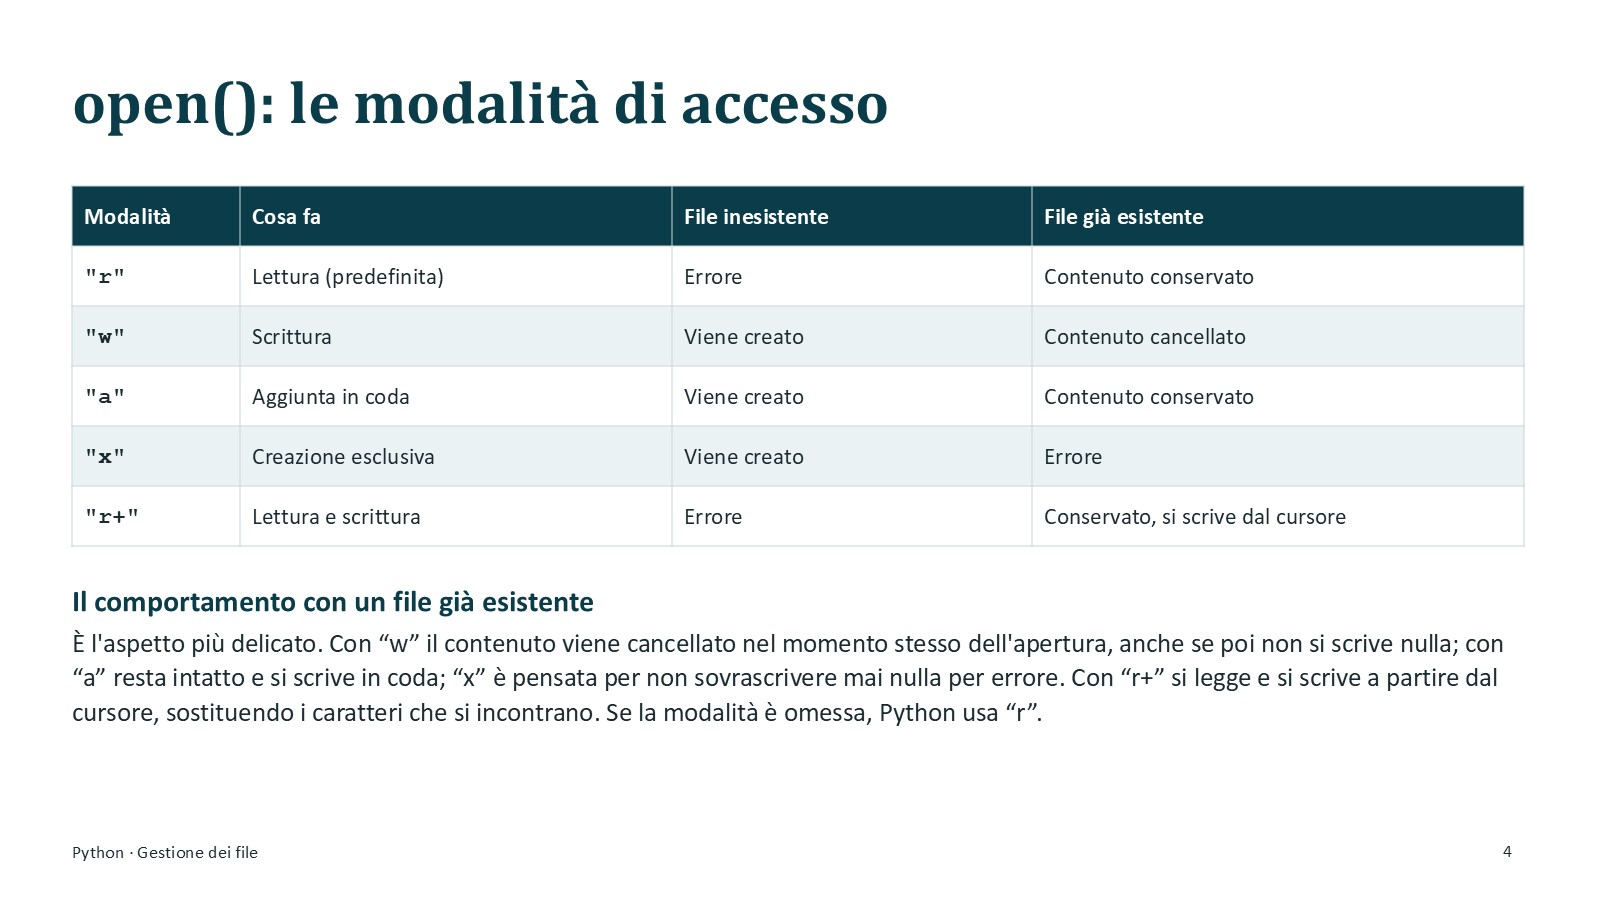

In [4]:
f = open("avvisi.txt", "w")
f.write("Prima comunicazione\n")
f.close()

In [8]:
f = open("avvisi.txt", "a")
f.write("Seconda comunicazione\n")
f.close()

**File e pathlib · Slide 5 · Leggere il contenuto di un file**

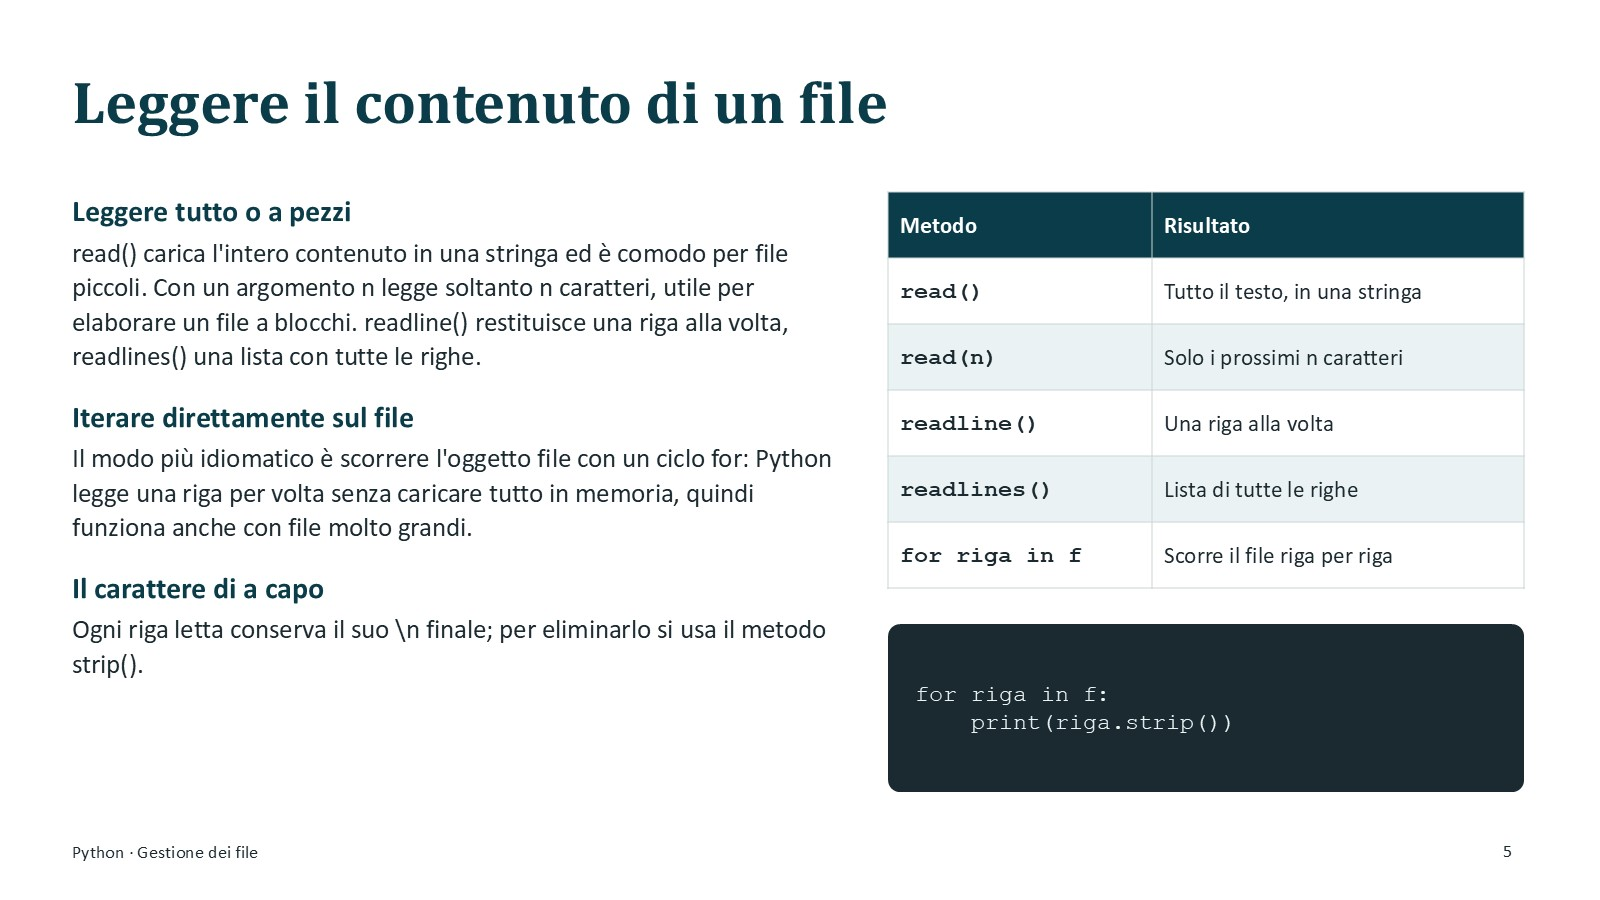

In [ ]:
f = open("note.txt")
print(f.read())
for riga in f:
    print(riga.strip())
f.close()

CIAO MONDO
A DOMANI


**File e pathlib · Slide 6 · Il cursore di lettura**

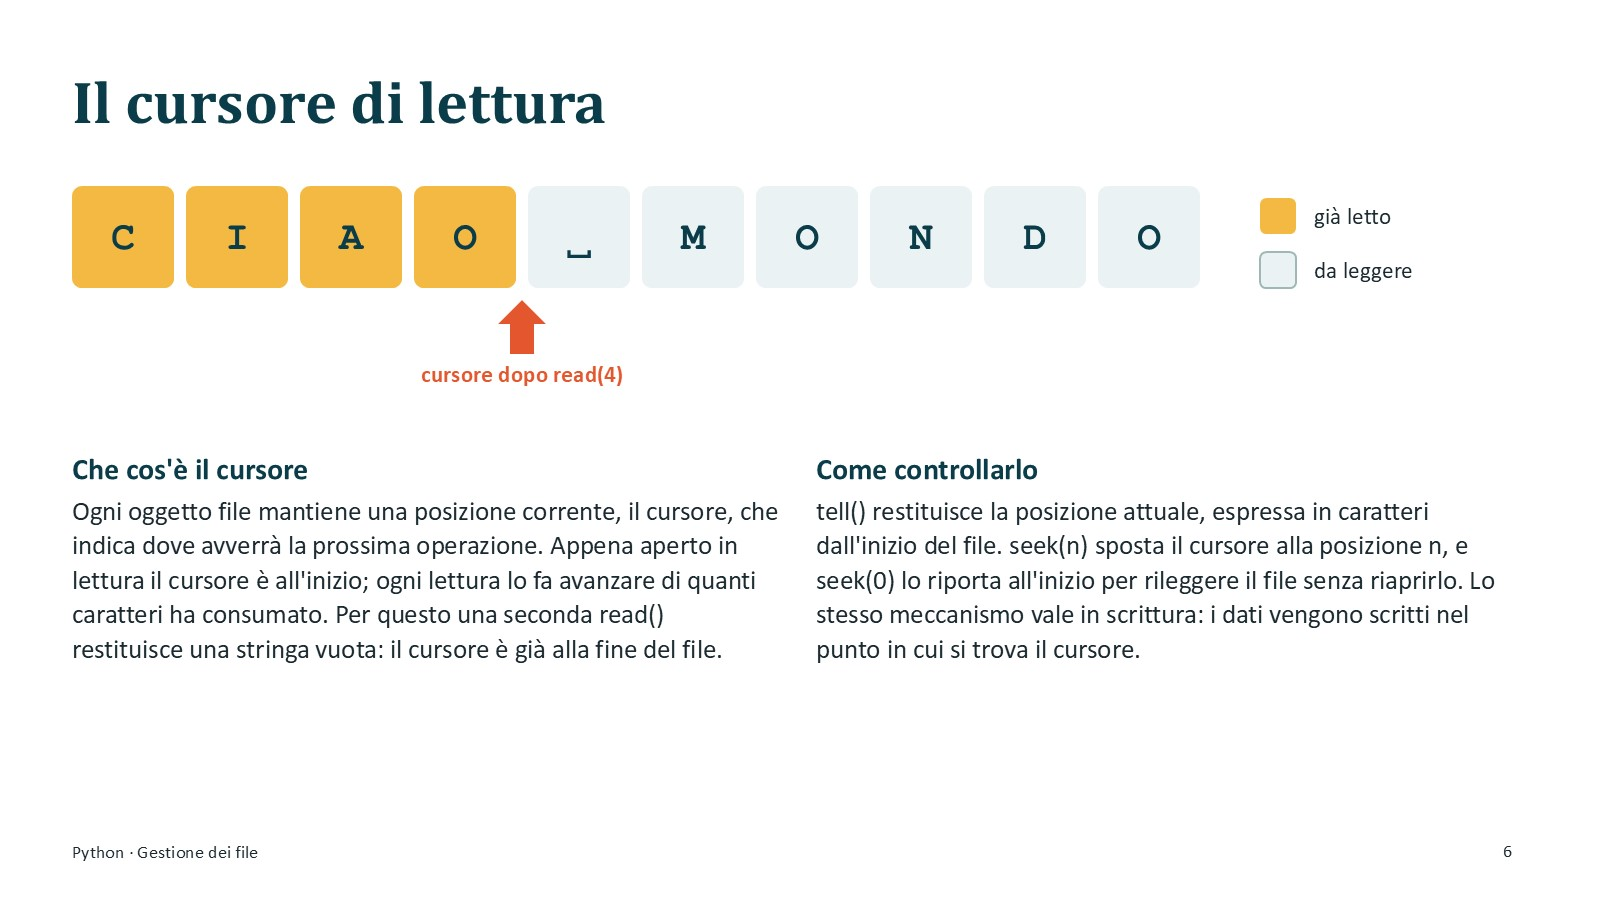

In [14]:
f = open("note.txt")
print(f.read(4))
print(f.tell())
print(f.read())
f.seek(0)
print(f.read(4))
f.close()

CIAO
4
 MONDO
A DOMANI
CIAO


**File e pathlib · Slide 7 · Scrivere in un file**

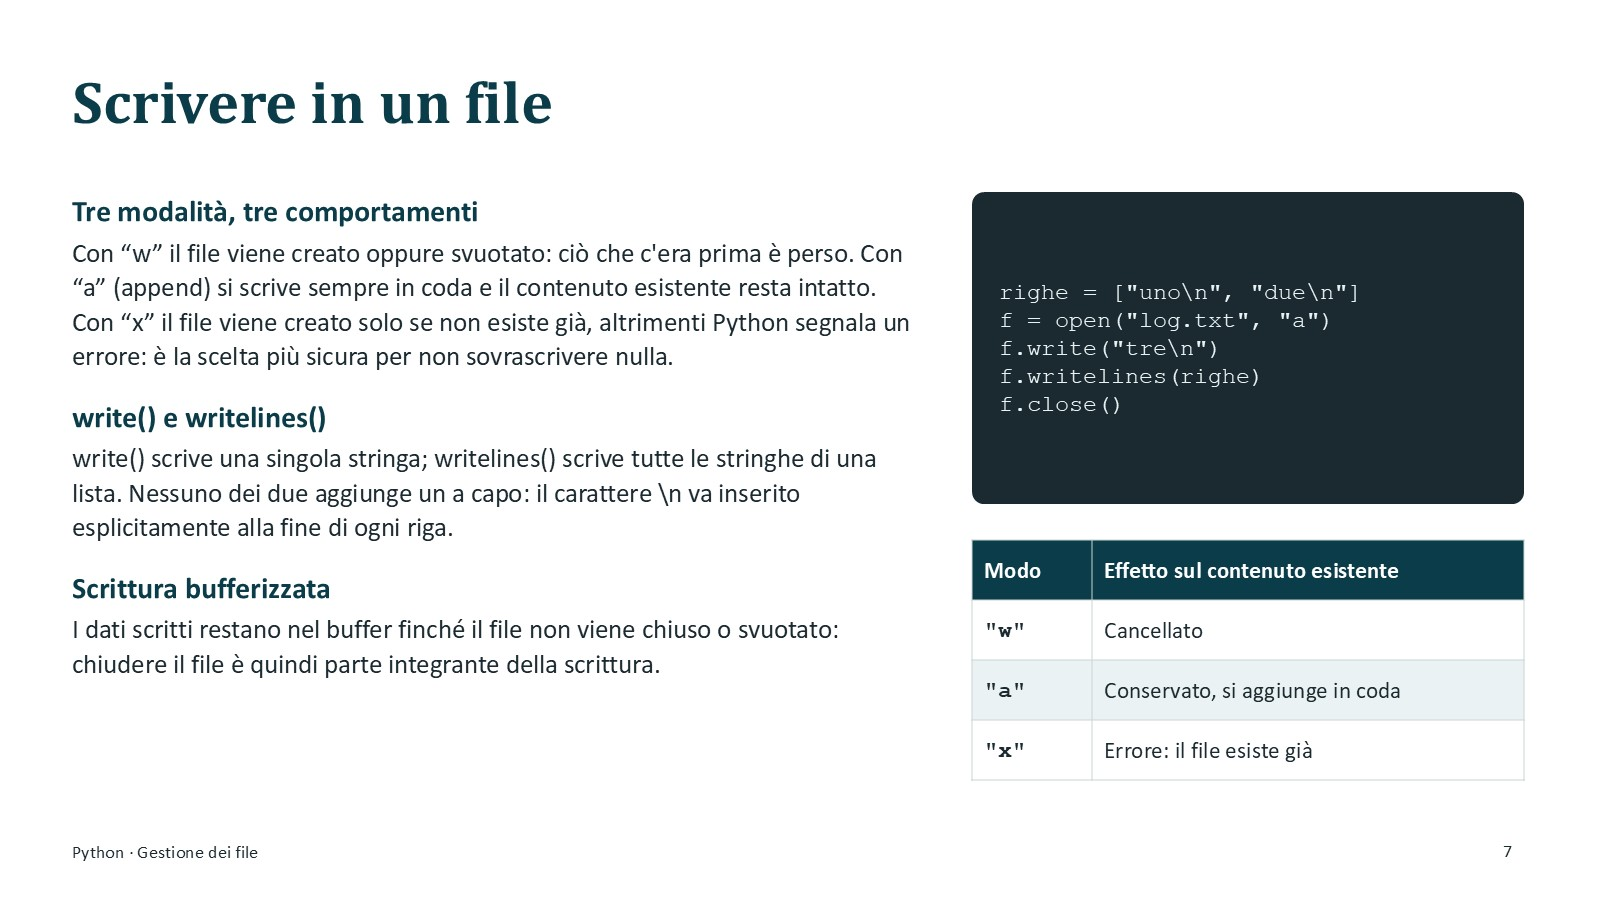

In [ ]:
righe = ["uno\n", "due\n"]
f = open("log.txt", "a")
f.write("tre\n")
f.writelines(righe)
f.close()

**File e pathlib · Slide 8 · Chiudere il file: l'istruzione with**

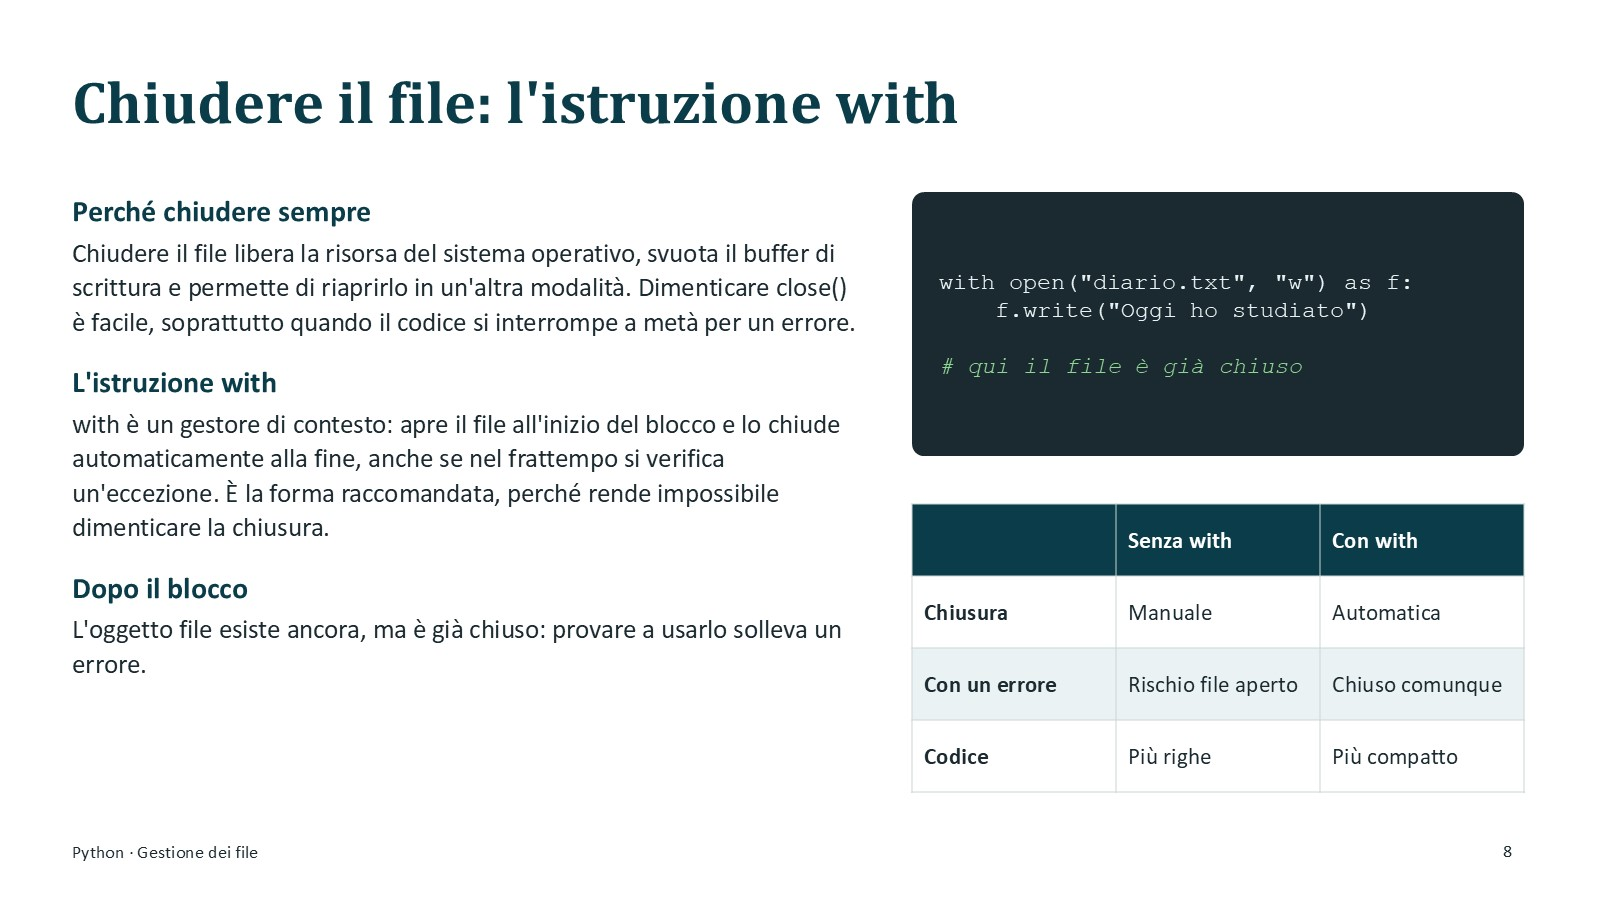

In [ ]:
with open("diario.txt", "w") as f:
    f.write("Oggi ho studiato")
 
# qui il file è già chiuso
print(f.closed)

**File e pathlib · Slide 10 · Il formato CSV**

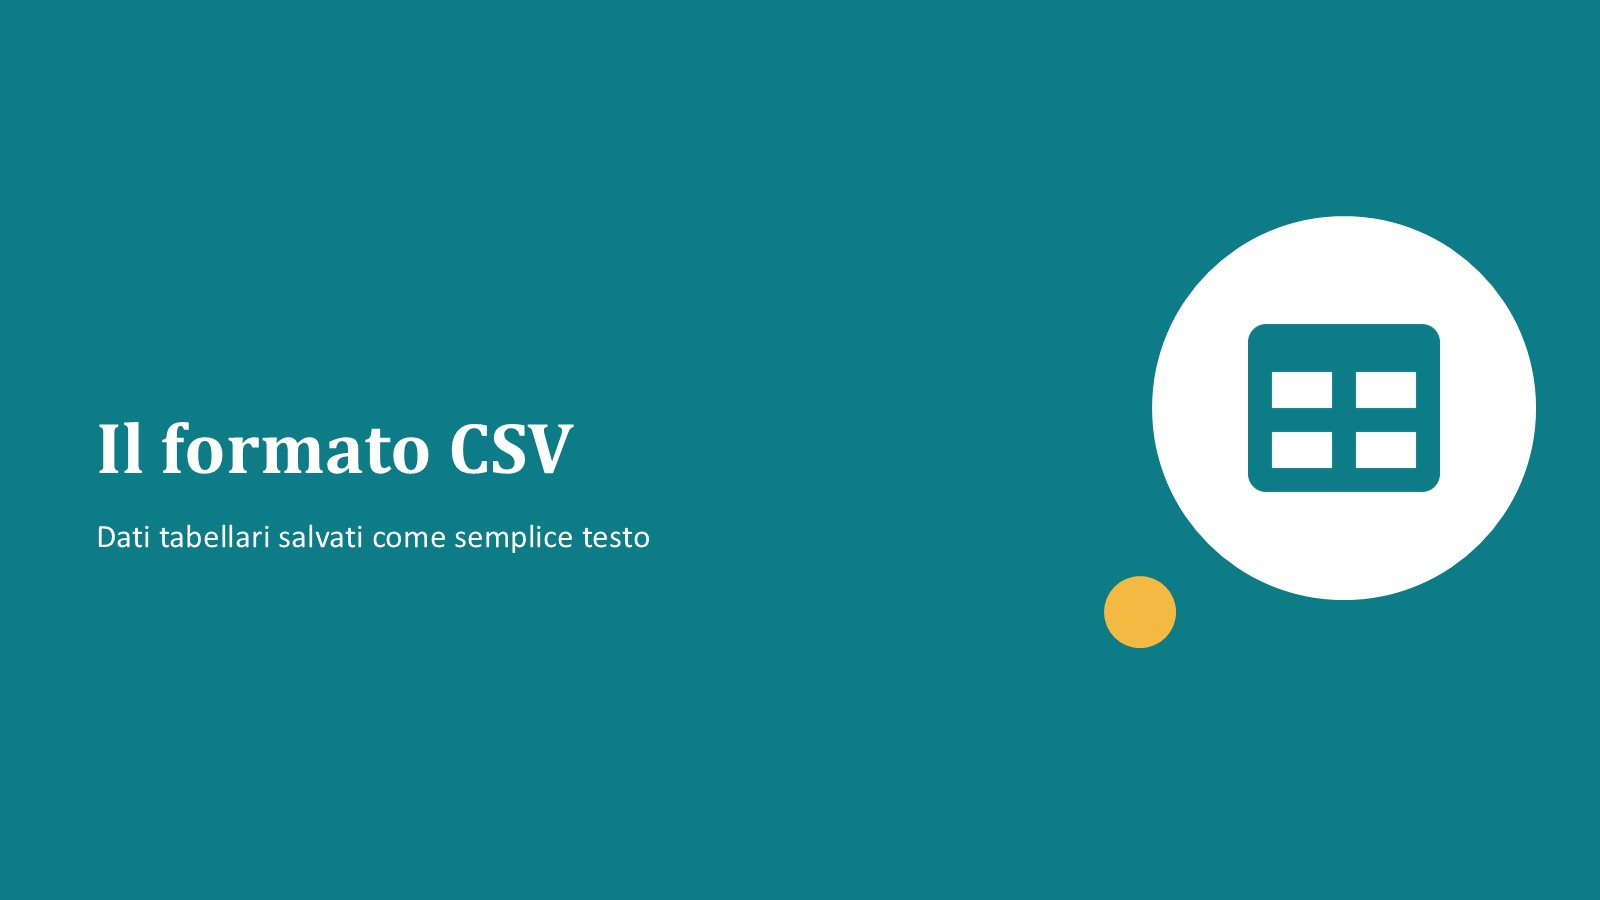

**File e pathlib · Slide 11 · Cos'è un file CSV**

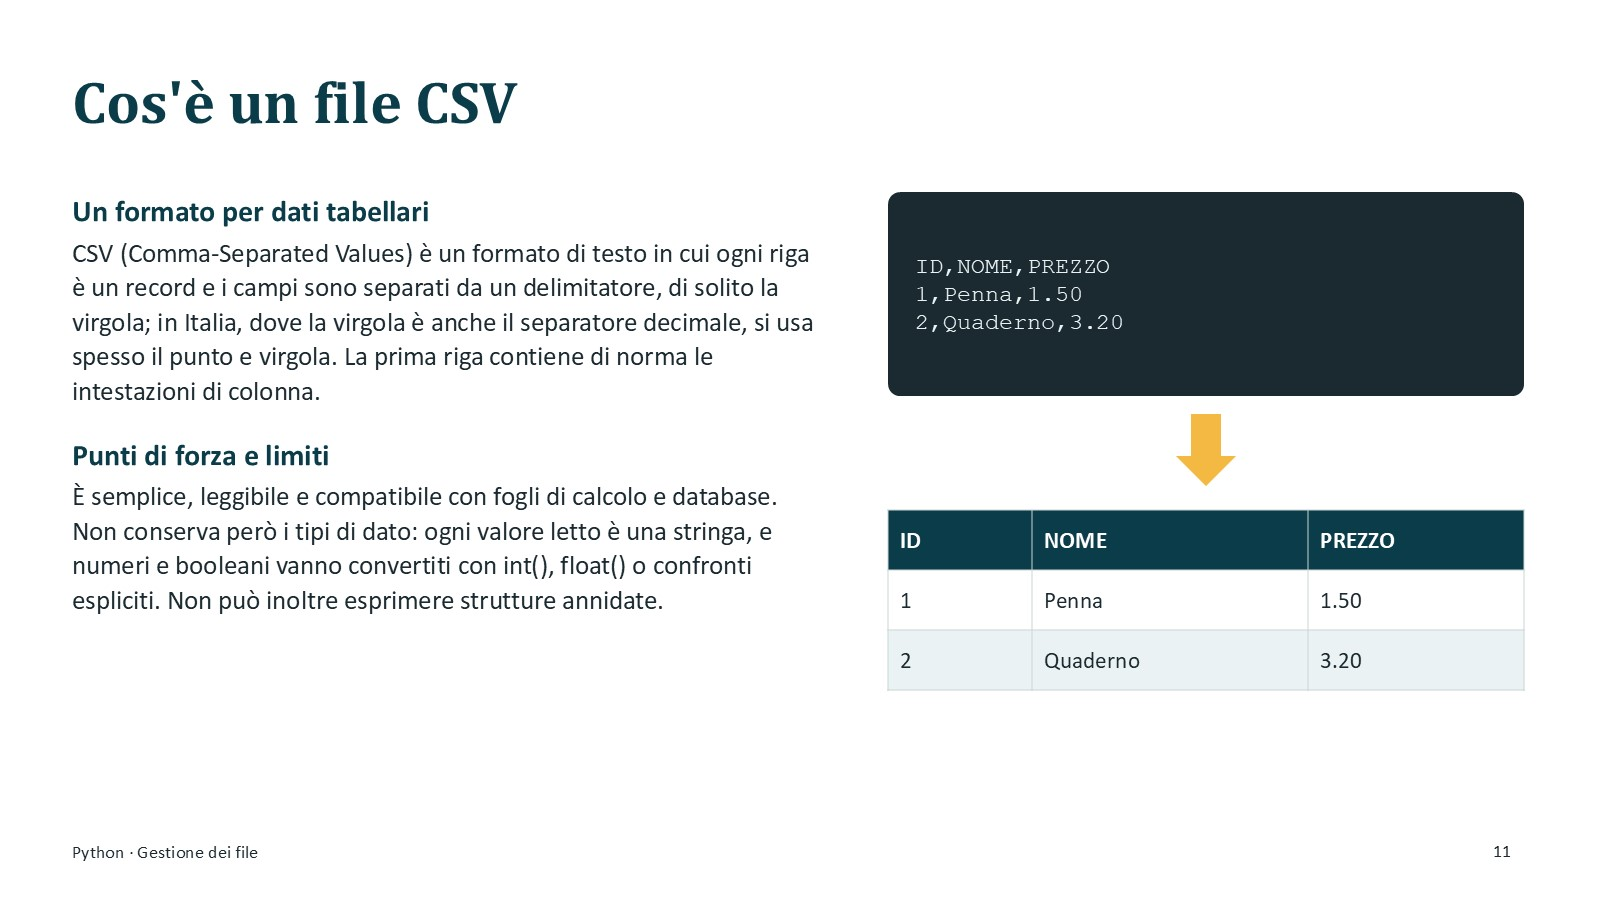

**Salva come `articoli.csv` nella cartella del notebook.**

```csv
ID,NOME,PREZZO
1,Penna,1.50
2,Quaderno,3.20
```

**File e pathlib · Slide 12 · Leggere e scrivere con il modulo csv**

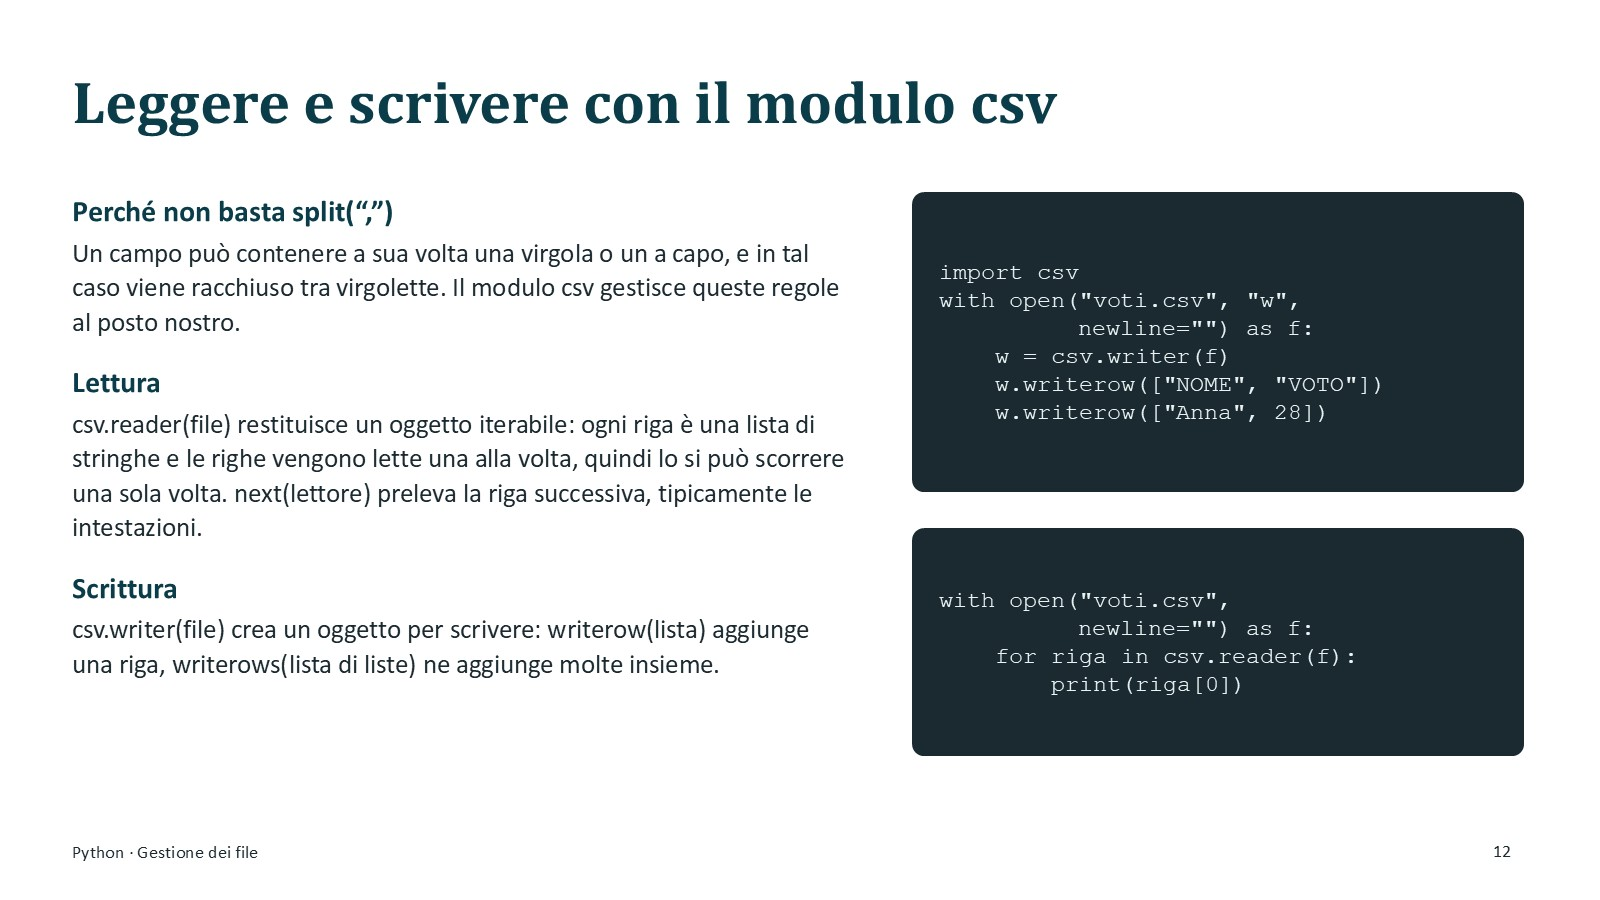

**File e pathlib · Slide 13 · I parametri newline ed encoding**

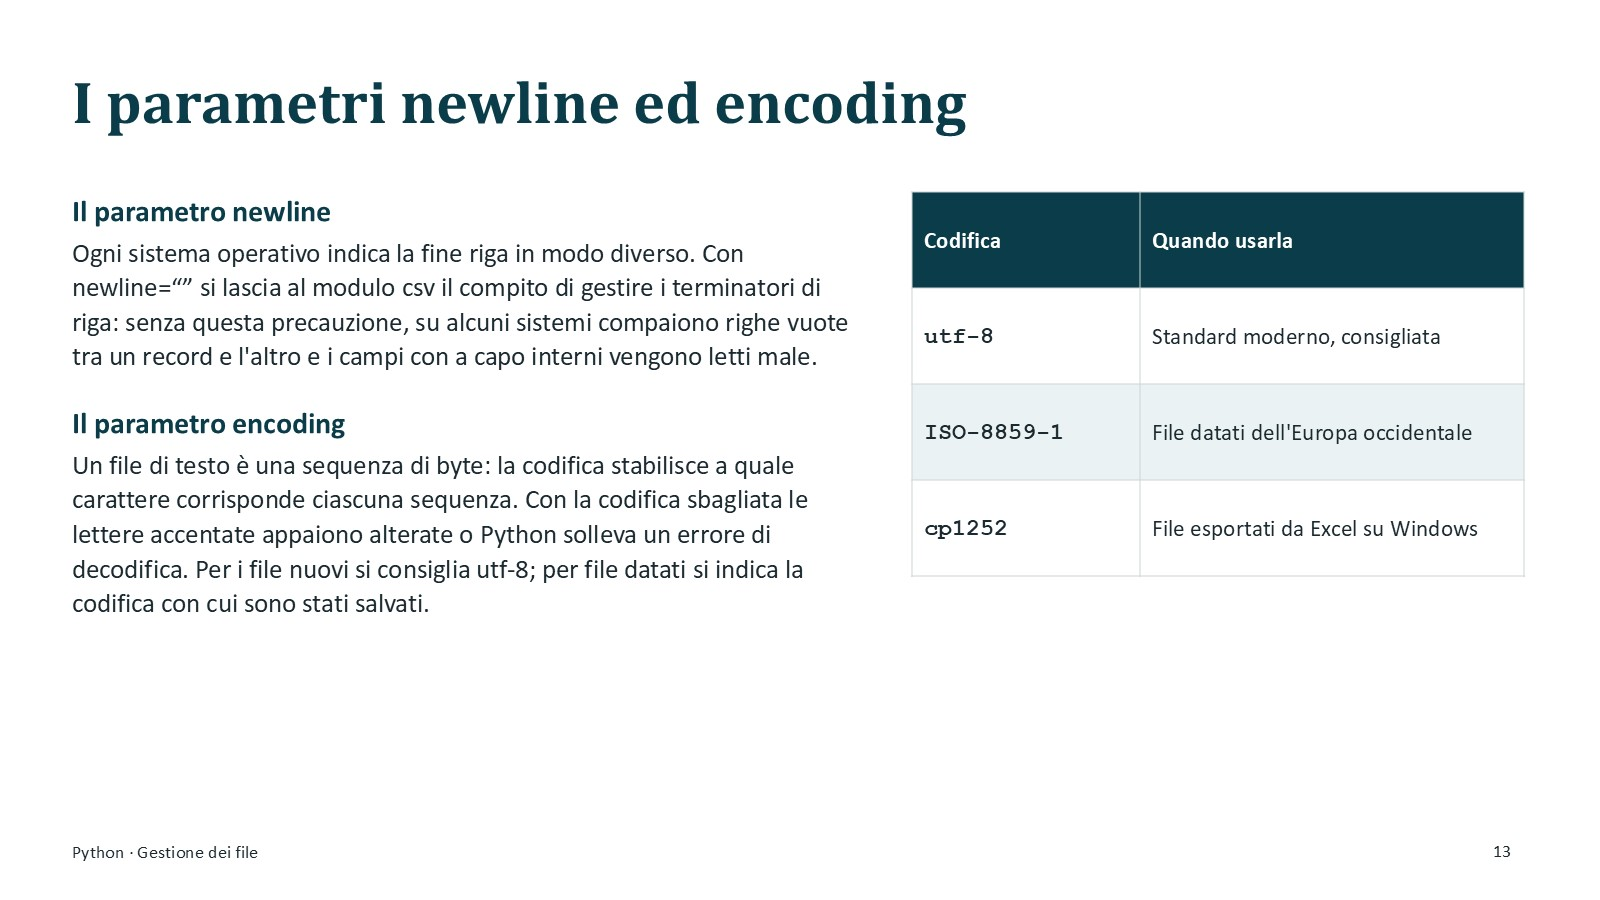

In [ ]:
import csv
with open("voti.csv", "w",
          newline="") as f:
    w = csv.writer(f)
    w.writerow(["NOME", "VOTO"])
    w.writerow(["Anna", 28])

with open("voti.csv",
          newline="") as f:
    for riga in csv.reader(f):
        print(riga[0])

In [1]:
import csv

with open("voti_utf8.csv", "w", newline="") as f:
    csv.writer(f).writerow(["Città", "Forlì"])

In [ ]:
import csv

with open("voti_utf8.csv", "w", newline="", encoding="utf-8") as f:
    csv.writer(f).writerow(["Città", "Forlì"])

**File e pathlib · Leggere le colonne e scrivere il report**

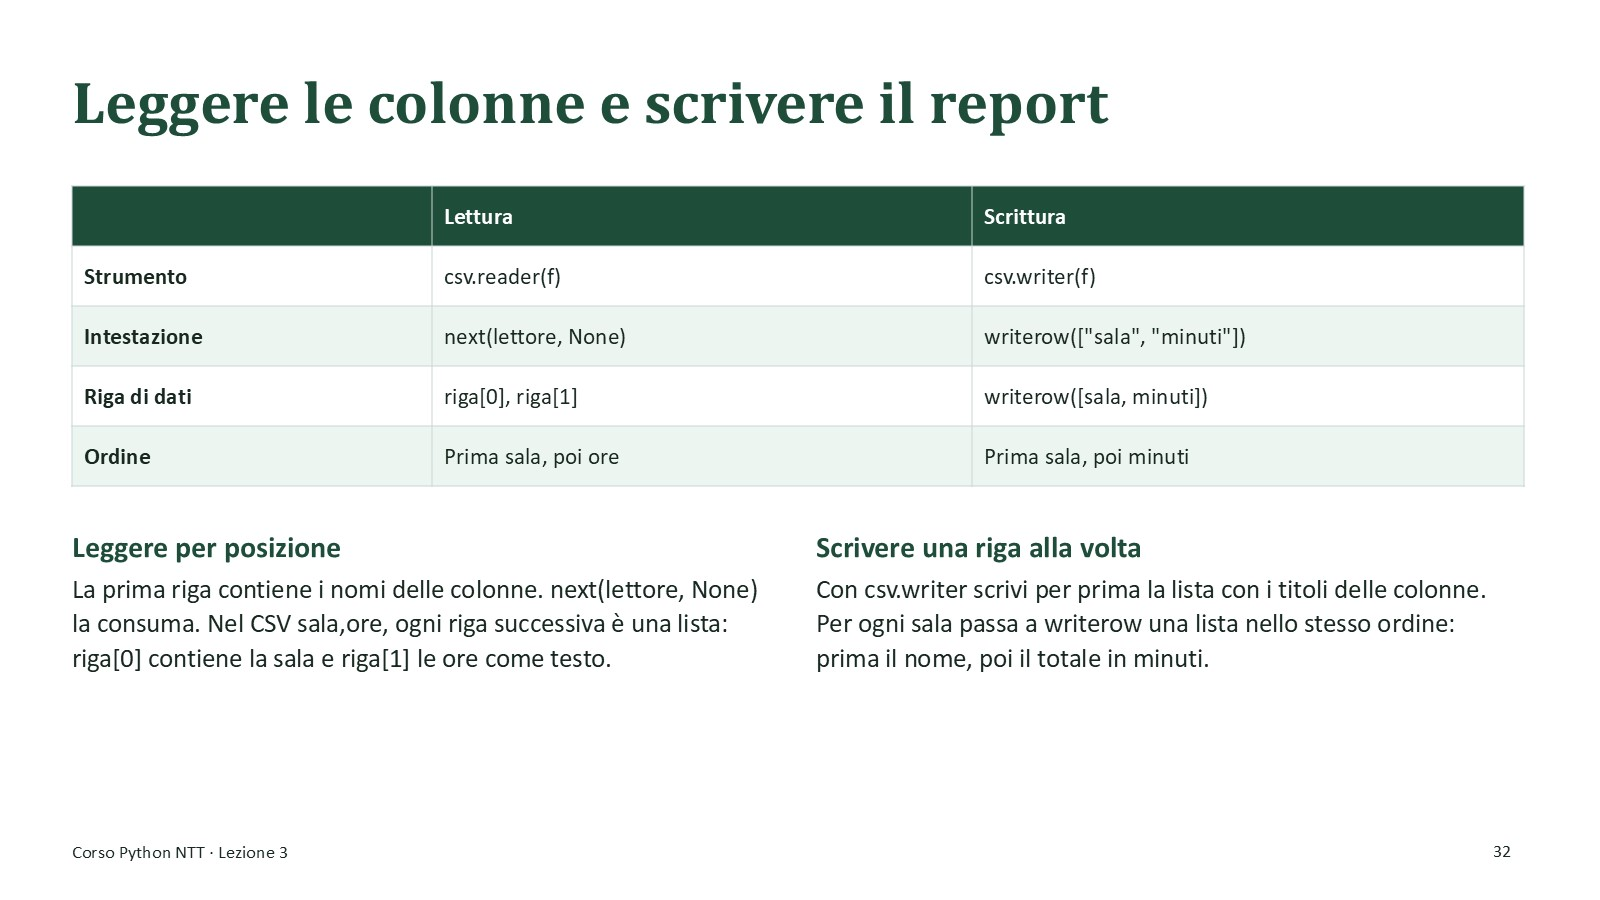

In [ ]:
import csv

with open("articoli.csv", newline="", encoding="utf-8") as f:
    lettore = csv.reader(f)
    next(lettore, None)  # Salta ID,NOME,PREZZO.
    articoli = list(lettore)

for riga in articoli:
    if riga[1] == "Penna":  # Il nome è nella seconda colonna.
        riga[2] = "1.70"    # Il prezzo è nella terza colonna.

with open("articoli_aggiornati.csv", "w", newline="", encoding="utf-8") as f:
    scrittore = csv.writer(f)
    scrittore.writerow(["ID", "NOME", "PREZZO"])
    for riga in articoli:
        scrittore.writerow(riga)

**File e pathlib · Slide 20 · Il modulo pathlib**

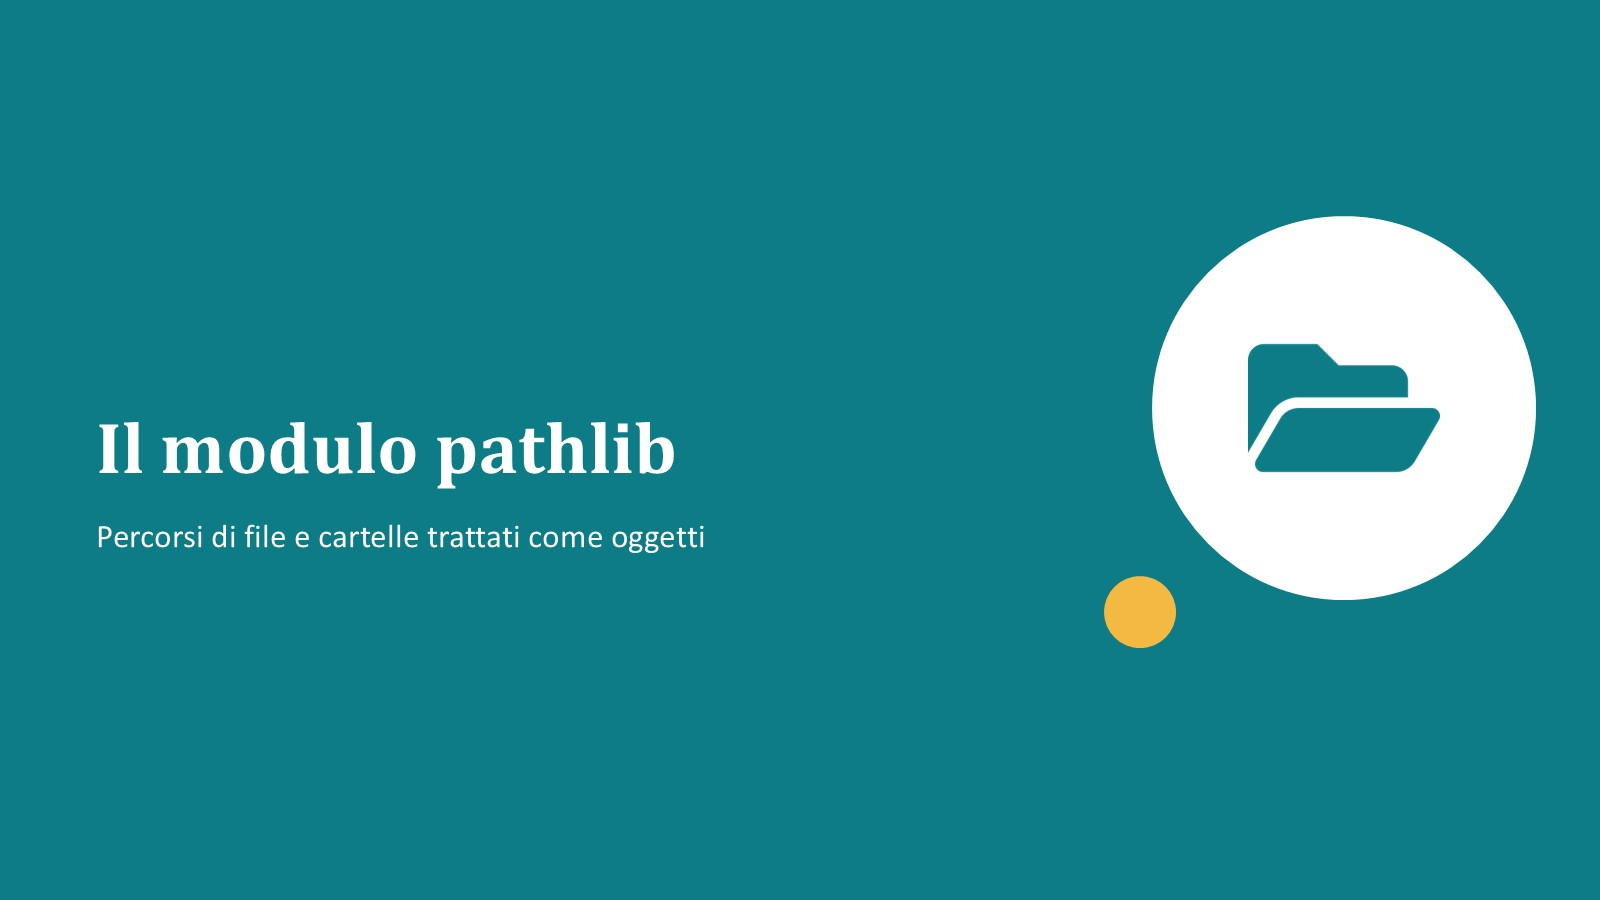

**File e pathlib · Slide 21 · Perché pathlib**

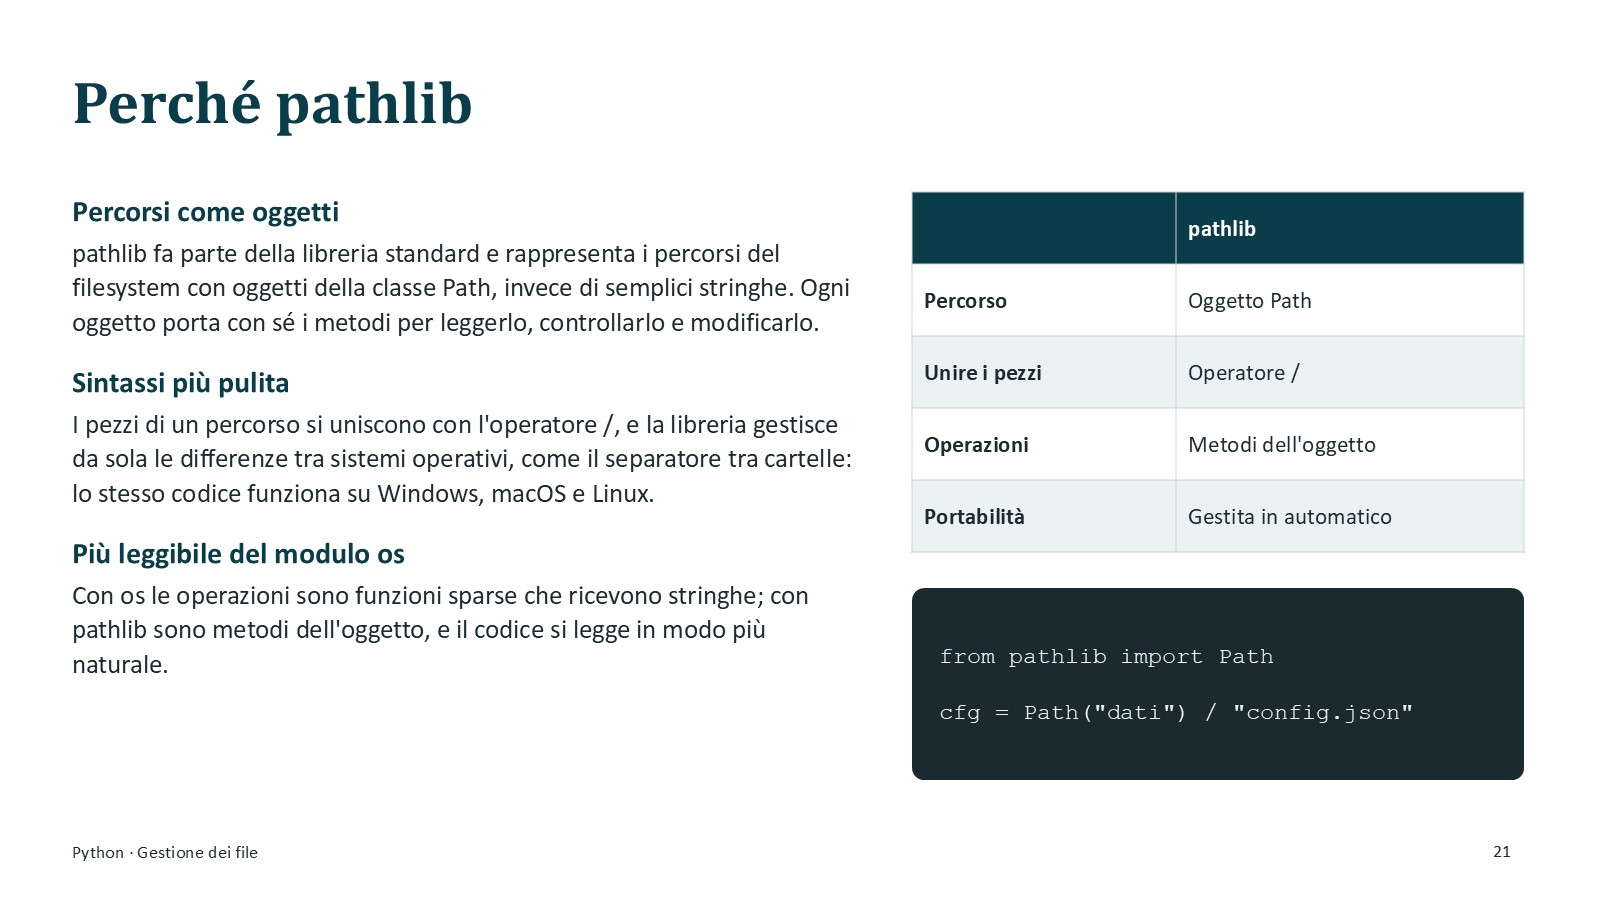

In [ ]:
from pathlib import Path
 
cfg = Path("dati") / "config.json"
print(cfg)

**File e pathlib · Slide 22 · Creare un oggetto Path**

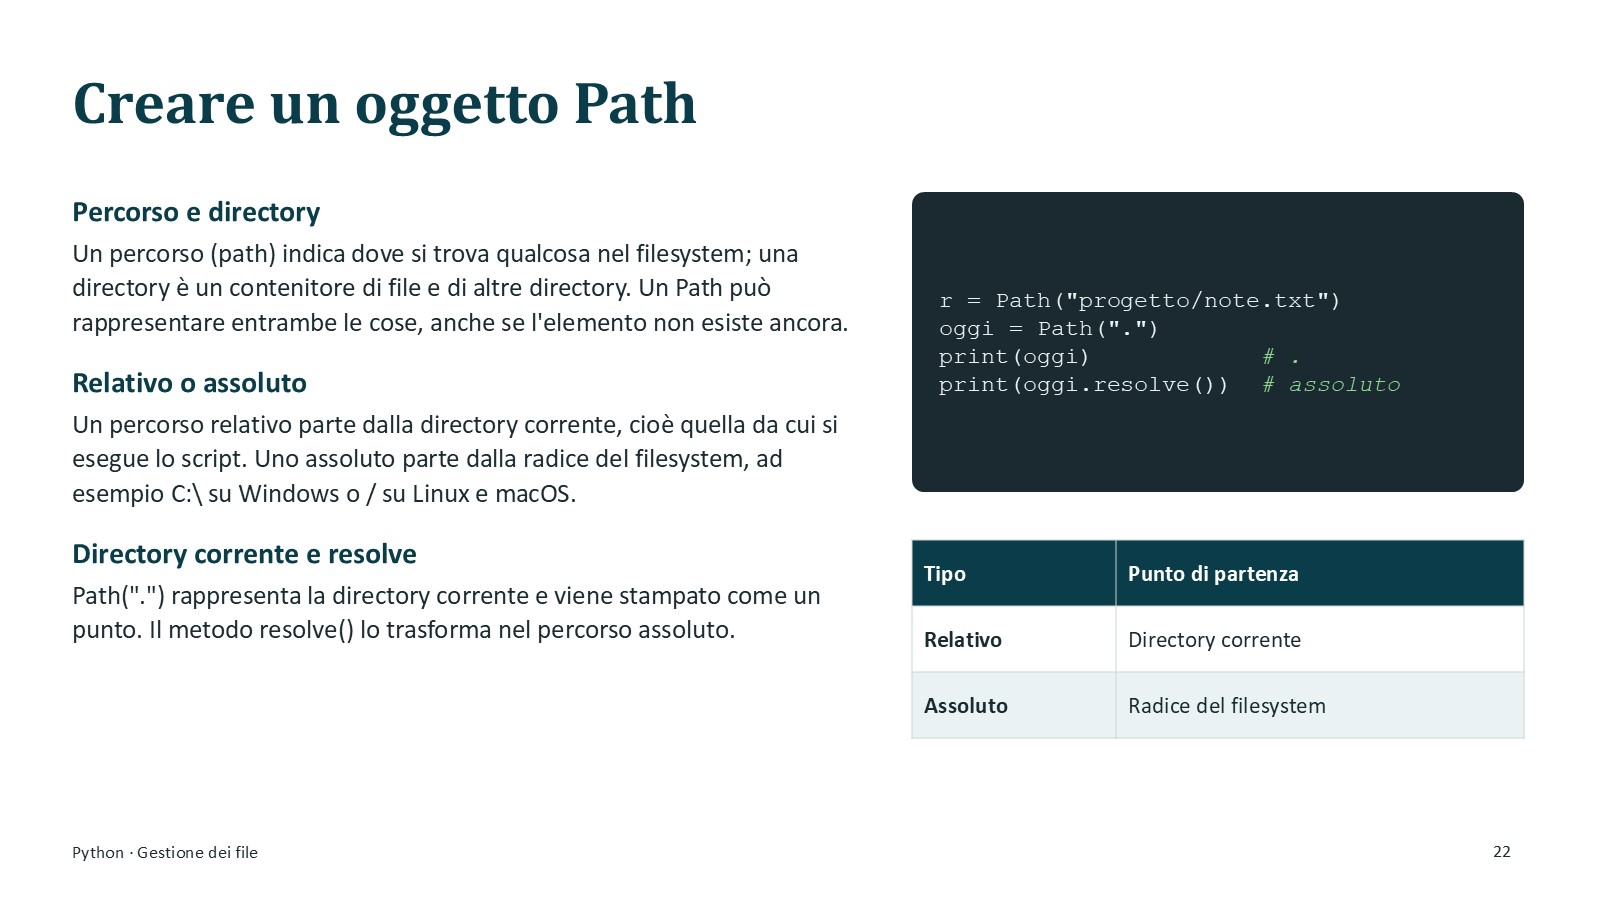

In [ ]:
from pathlib import Path

r = Path("progetto/note.txt")
oggi = Path(".")
print(oggi)            # .
print(oggi.resolve())  # assoluto

**File e pathlib · Slide 23 · Controllare un percorso**

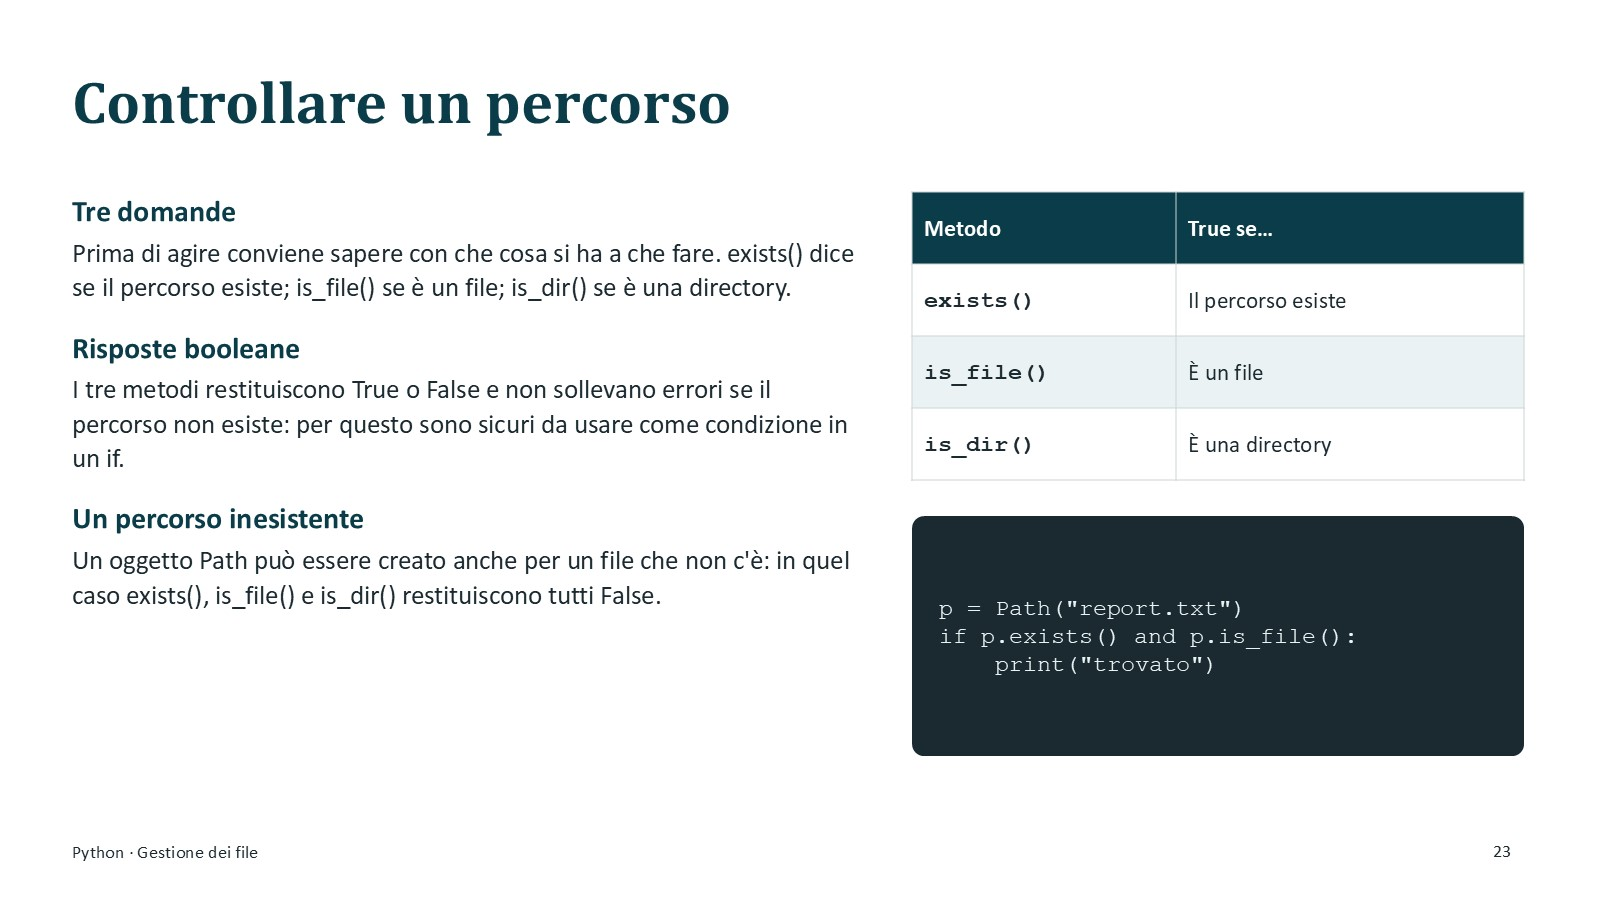

In [ ]:
from pathlib import Path

p = Path("report.txt")
if p.exists() and p.is_file():
    print("trovato")
print(p.exists(), p.is_file(), p.is_dir())

**File e pathlib · Slide 24 · Creare cartelle e file**

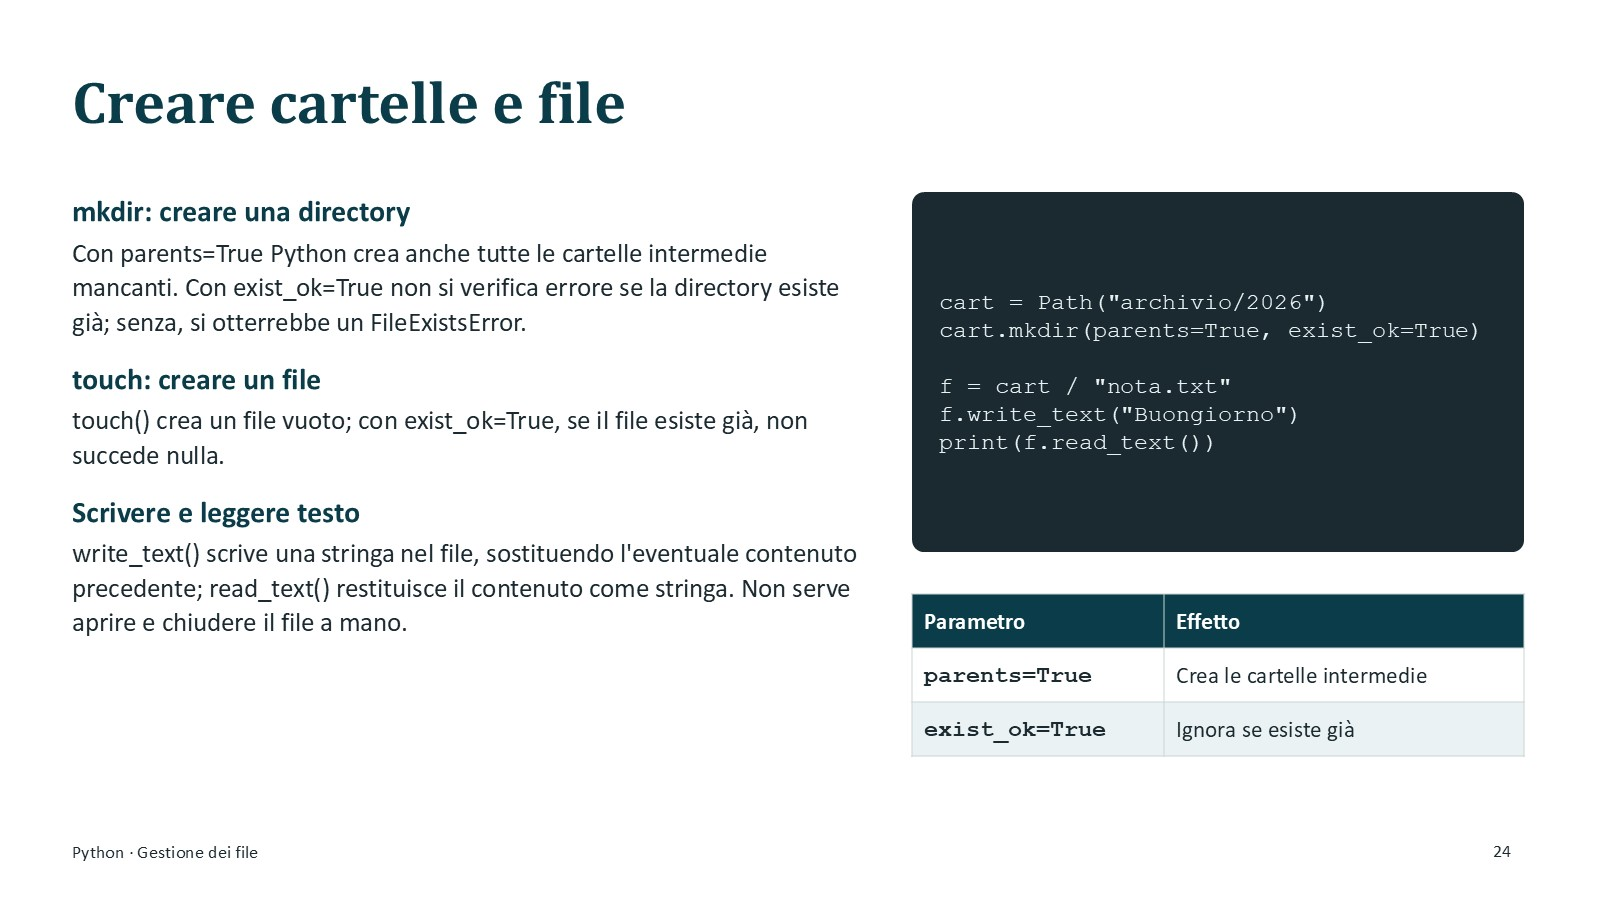

In [ ]:
from pathlib import Path

cart = Path("archivio/2026")
cart.mkdir(parents=True, exist_ok=True)
 
f = cart / "nota.txt"
f.write_text("Buongiorno", encoding="utf-8")
print(f.read_text(encoding="utf-8"))

## Usare insieme modulo, oggetti e file

Una riga contiene dati di testo. La conversione prepara il valore numerico, la classe lo conserva in un oggetto e il metodo lo usa per calcolare i minuti.

### E01 · Quanti minuti di sala dobbiamo riservare?

La segreteria riceve un CSV con la sala e le ore di ciascuna prenotazione. Una sala può comparire più volte. Prepara un report con una riga per ogni sala che abbia almeno una prenotazione valida e il totale dei minuti da riservare. Conta come scarto ogni durata illeggibile, nulla o negativa.

**Prepara il progetto.** Crea una cartella `esercizio_sale` e aprila in VS Code. Al suo interno crea `richieste_sale.csv` copiando i dati riportati qui sotto.

**Scrivi il modulo.** In `prenotazioni.py` definisci la classe `Prenotazione` con gli attributi sala e ore. Il metodo `minuti()` deve restituire la durata in minuti.

**Scrivi il programma.** Crea `report_sale.py` nella stessa cartella. Importa `prenotazioni` e prova il metodo su una prenotazione da due ore. Aggiungi un commento che identifichi modulo e classe. Leggi il CSV con `with` e `csv.reader`. Salta l’intestazione. In ogni riga trovi la sala in `riga[0]` e le ore in `riga[1]`. Per ogni riga valida crea una prenotazione e usa il suo metodo per aggiornare il totale per sala.

**Esegui e controlla.** Dal terminale di `esercizio_sale` lancia `python report_sale.py`. Con `csv.writer` crea `minuti_sale.csv`. Scrivi prima l’intestazione `sala,minuti` con `writerow()`, poi una riga per sala. Stampa il numero di scarti. Riapri il CSV prodotto: Blu deve includere entrambe le prenotazioni e Verde deve comparire una sola volta. Aggiungi una richiesta valida di un’ora per Verde nel CSV di ingresso, rilancia lo script e confronta i due risultati.

#### Richiami teorici

| Quando leggi il codice | Cosa indica |
|---|---|
| `modulo.Classe(...)` | Python cerca la classe nel namespace del modulo e crea un’istanza. |
| `oggetto.metodo()` | Il metodo lavora sull’istanza indicata a sinistra del punto. |
| `with` e modalità di apertura | `r` legge; `w` crea il file o ne sostituisce il contenuto. Il blocco delimita l’uso del file. |
| Campi di un CSV | `csv.reader` restituisce liste di stringhe. `next(lettore, None)` salta la prima riga. Gli indici 0 e 1 indicano la prima e la seconda colonna. |

**Contenuto di `richieste_sale.csv`**

```csv
sala,ore
Blu,2
Verde,1
Blu,1
Rossa,?
Verde,0
```